#Étape B : la cellule de reprise rapide

In [1]:
# ======================= REPRISE RAPIDE =======================
# À exécuter SEULE après une déconnexion, à la place de "Tout exécuter".
!pip -q install sentence-transformers

import os, json, gc
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from collections import Counter
from google.colab import drive
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (coverage_error, label_ranking_average_precision_score,
                             label_ranking_loss)

# --- 1. Drive et données sauvegardées ---
drive.mount("/content/drive")
DOSSIER = "/content/drive/MyDrive/memoire_sts/resultats"

with open(f"{DOSSIER}/taches.json", encoding="utf-8") as f:
    brut = json.load(f)
TACHES = {nom: {"requetes": t["requetes"], "etiquettes": t["etiquettes"],
                "verite": {k: set(v) for k, v in t["verite"].items()}}
          for nom, t in brut.items()}

FICHIER = f"{DOSSIER}/resultats_attack.json"
resultats = json.load(open(FICHIER)) if os.path.exists(FICHIER) else {}

MODELES = {
    "MiniLM":      "sentence-transformers/all-MiniLM-L12-v2",
    "MPNet":       "sentence-transformers/all-mpnet-base-v2",
    "RoBERTa":     "sentence-transformers/all-roberta-large-v1",
    "BGE":         "BAAI/bge-large-en-v1.5",
    "GTE":         "thenlper/gte-large",
    "ATTACK-BERT": "basel/ATTACK-BERT",
}

# --- 2. Fonctions de préparation et de mesure ---
def preparer(tache):
    ids_req = list(tache["requetes"])
    ids_etiq = list(tache["etiquettes"])
    textes_req = [tache["requetes"][i]["texte"] for i in ids_req]
    textes_etiq = [tache["etiquettes"][i]["texte"] for i in ids_etiq]
    Y = np.array([[1 if e in tache["verite"][r] else 0 for e in ids_etiq]
                  for r in ids_req])
    return textes_req, textes_etiq, Y

def recall_at_k(Y, S, k):
    top_k = np.argsort(-S, axis=1)[:, :k]
    trouves = np.take_along_axis(Y, top_k, axis=1).sum(axis=1)
    return (trouves / Y.sum(axis=1)).mean()

def plafond_recall(Y, k):
    p = Y.sum(axis=1)
    return np.mean(np.minimum(k, p) / p)

def evaluer(Y, S):
    return {"CE":   coverage_error(Y, S),
            "LRAP": label_ranking_average_precision_score(Y, S),
            "LRL":  label_ranking_loss(Y, S),
            "R@1":  recall_at_k(Y, S, 1),
            "R@3":  recall_at_k(Y, S, 3),
            "R@5":  recall_at_k(Y, S, 5)}

# --- 3. Fonctions de calcul des similarités ---
def similarites_modele(modele, textes_req, textes_etiq):
    E_req = modele.encode(textes_req, normalize_embeddings=True, batch_size=32)
    E_etiq = modele.encode(textes_etiq, normalize_embeddings=True, batch_size=32)
    return E_req @ E_etiq.T

def similarites_tfidf(textes_req, textes_etiq):
    v = TfidfVectorizer(stop_words="english").fit(textes_req + textes_etiq)
    return (v.transform(textes_req) @ v.transform(textes_etiq).T).toarray()

# --- 4. Fonctions de sauvegarde, de reprise et d'affichage ---
def sauver():
    with open(FICHIER, "w") as f:
        json.dump(resultats, f, indent=1)

def charger_S(modele, nom_tache):
    S = np.load(f"{DOSSIER}/S_{modele}_{nom_tache}.npy")
    _, _, Y = preparer(TACHES[nom_tache])
    assert S.shape == Y.shape, f"Taille incohérente pour {modele}/{nom_tache}"
    return S, Y

def calculer_references(taches):
    for nom_tache, tache in taches.items():
        if nom_tache in resultats.get("TF-IDF", {}):
            continue
        tr, te, Y = preparer(tache)
        S = similarites_tfidf(tr, te)
        resultats.setdefault("TF-IDF", {})[nom_tache] = {k: float(v) for k, v in evaluer(Y, S).items()}
        rng = np.random.default_rng(0)
        essais = [evaluer(Y, rng.random(Y.shape)) for _ in range(100)]
        resultats.setdefault("Hasard", {})[nom_tache] = {k: float(np.mean([e[k] for e in essais]))
                                                         for k in essais[0]}
    sauver()

def lancer_modeles(taches):
    for nom_modele, chemin in MODELES.items():
        a_faire = [t for t in taches if t not in resultats.get(nom_modele, {})]
        if not a_faire:
            print(f"{nom_modele} : tout est déjà calculé")
            continue
        print(f"\n=== {nom_modele} : {a_faire} ===")
        modele = SentenceTransformer(chemin)
        resultats.setdefault(nom_modele, {})
        for nom_tache in a_faire:
            tr, te, Y = preparer(taches[nom_tache])
            S = similarites_modele(modele, tr, te).astype(np.float64)
            np.save(f"{DOSSIER}/S_{nom_modele}_{nom_tache}.npy", S)
            resultats[nom_modele][nom_tache] = {k: float(v) for k, v in evaluer(Y, S).items()}
            print(f"  {nom_tache}: LRAP = {resultats[nom_modele][nom_tache]['LRAP']:.3f}")
            sauver()
        del modele
        gc.collect()
        torch.cuda.empty_cache()

def tableau(metrique):
    df = pd.DataFrame({m: {t: r[t][metrique] for t in TACHES if t in r}
                       for m, r in resultats.items()}).T
    df["Moyenne"] = df.mean(axis=1)
    return df.round(3)

# --- 5. Vérification ---
for nom, t in TACHES.items():
    _, _, Y = preparer(t)
    print(f"{nom}: {Y.shape[0]} requêtes, {Y.shape[1]} étiquettes, {Y.sum()} paires")
print("\nMéthodes déjà calculées :", list(resultats))
display(tableau("LRAP"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TecTac: 196 requêtes, 14 étiquettes, 227 paires
SubTec: 411 requêtes, 196 étiquettes, 411 paires
SubTac: 411 requêtes, 14 étiquettes, 558 paires
CapTac: 177 requêtes, 14 étiquettes, 275 paires
CapTec: 177 requêtes, 196 étiquettes, 238 paires
CapSub: 112 requêtes, 411 étiquettes, 161 paires
CveTac: 815 requêtes, 14 étiquettes, 1844 paires
CveTec: 815 requêtes, 196 étiquettes, 1648 paires
CveSub: 283 requêtes, 411 étiquettes, 334 paires
DefTac: 12 requêtes, 139 étiquettes, 785 paires
DefTec: 134 requêtes, 139 étiquettes, 2291 paires
DefSub: 257 requêtes, 139 étiquettes, 4089 paires

Méthodes déjà calculées : ['TF-IDF', 'Hasard', 'MiniLM', 'MPNet', 'RoBERTa', 'BGE', 'GTE', 'ATTACK-BERT', 'E-SLMs+AB']


,TecTac,SubTec,SubTac,CapTac,CapTec,CapSub,CveTac,CveTec,CveSub,DefTac,DefTec,DefSub,Moyenne
TF-IDF,0.667,0.632,0.585,0.323,0.406,0.480,0.451,0.139,0.181,0.519,0.271,0.269,0.410
Hasard,0.242,0.030,0.252,0.262,0.032,0.017,0.307,0.035,0.016,0.489,0.152,0.143,0.165
MiniLM,0.703,0.640,0.528,0.445,0.467,0.584,0.466,0.215,0.195,0.553,0.299,0.300,0.449
MPNet,0.704,0.654,0.620,0.471,0.565,0.636,0.451,0.160,0.150,0.570,0.303,0.310,0.466
RoBERTa,0.683,0.623,0.573,0.495,0.538,0.628,0.414,0.187,0.163,0.561,0.282,0.286,0.453
BGE,0.776,0.660,0.616,0.462,0.485,0.603,0.511,0.200,0.238,0.528,0.256,0.269,0.467
GTE,0.758,0.668,0.629,0.468,0.488,0.575,0.522,0.240,0.193,0.527,0.259,0.272,0.467
ATTACK-BERT,0.780,0.673,0.731,0.577,0.569,0.620,0.477,0.197,0.217,0.556,0.298,0.315,0.501
E-SLMs+AB,0.795,0.726,0.746,0.563,0.586,0.632,0.510,0.223,0.235,0.554,0.304,0.318,0.516


In [ ]:
for m in ["CE", "LRL", "R@5"]:
    print(m)
    display(tableau(m))

CE


,TecTac,SubTec,SubTac,CapTac,CapTec,CapSub,CveTac,CveTec,CveSub,DefTac,DefTec,DefSub,Moyenne
TF-IDF,3.020,5.625,4.431,8.638,26.571,35.036,9.006,78.405,118.671,139.000,128.761,127.004,57.014
Hasard,7.858,98.699,8.297,8.691,108.294,229.443,9.651,124.391,217.753,137.633,124.791,125.120,100.052
MiniLM,3.000,5.467,4.759,6.593,17.107,29.188,8.133,55.867,67.735,137.333,110.896,106.323,46.033
MPNet,2.847,4.745,3.657,6.390,13.893,27.366,7.966,62.239,59.845,136.417,107.060,104.868,44.774
RoBERTa,2.694,5.844,4.080,6.023,15.802,21.884,8.448,58.816,84.739,136.500,103.231,103.926,45.999
BGE,2.464,4.866,3.667,6.141,15.192,28.250,7.416,53.104,66.558,136.583,105.612,105.673,44.627
GTE,2.561,4.187,3.594,5.921,14.508,26.098,7.182,53.864,60.011,136.000,105.799,106.432,43.846
ATTACK-BERT,2.286,3.645,2.993,5.153,12.435,20.009,7.194,59.042,55.420,136.833,105.590,101.374,42.664
E-SLMs+AB,2.209,3.027,2.832,5.186,11.068,17.482,6.956,51.826,48.081,137.417,102.567,98.074,40.560


LRL


,TecTac,SubTec,SubTac,CapTac,CapTec,CapSub,CveTac,CveTec,CveSub,DefTac,DefTec,DefSub,Moyenne
TF-IDF,0.133,0.024,0.202,0.469,0.101,0.066,0.433,0.281,0.268,0.679,0.469,0.439,0.297
Hasard,0.500,0.501,0.501,0.503,0.502,0.502,0.500,0.501,0.499,0.499,0.501,0.500,0.501
MiniLM,0.128,0.023,0.222,0.341,0.063,0.048,0.358,0.183,0.146,0.440,0.340,0.330,0.218
MPNet,0.118,0.019,0.150,0.322,0.046,0.045,0.353,0.214,0.128,0.402,0.312,0.306,0.201
RoBERTa,0.110,0.025,0.185,0.309,0.054,0.034,0.391,0.192,0.177,0.405,0.327,0.326,0.211
BGE,0.089,0.020,0.156,0.315,0.051,0.040,0.307,0.177,0.146,0.452,0.341,0.339,0.203
GTE,0.096,0.016,0.148,0.301,0.050,0.039,0.289,0.171,0.129,0.453,0.349,0.344,0.199
ATTACK-BERT,0.077,0.014,0.103,0.230,0.043,0.034,0.300,0.204,0.118,0.444,0.323,0.307,0.183
E-SLMs+AB,0.071,0.010,0.094,0.237,0.037,0.027,0.274,0.175,0.102,0.433,0.311,0.301,0.173


R@5


,TecTac,SubTec,SubTac,CapTac,CapTec,CapSub,CveTac,CveTec,CveSub,DefTac,DefTec,DefSub,Moyenne
TF-IDF,0.863,0.781,0.751,0.432,0.535,0.615,0.594,0.178,0.249,0.041,0.121,0.104,0.439
Hasard,0.356,0.026,0.357,0.356,0.027,0.012,0.357,0.025,0.011,0.037,0.036,0.036,0.136
MiniLM,0.848,0.788,0.735,0.596,0.578,0.703,0.535,0.259,0.280,0.048,0.138,0.133,0.470
MPNet,0.894,0.813,0.842,0.617,0.697,0.691,0.542,0.196,0.231,0.055,0.137,0.131,0.487
RoBERTa,0.910,0.764,0.793,0.645,0.672,0.756,0.488,0.242,0.226,0.037,0.121,0.123,0.481
BGE,0.914,0.808,0.829,0.615,0.619,0.712,0.572,0.225,0.311,0.044,0.106,0.111,0.489
GTE,0.896,0.827,0.842,0.630,0.629,0.702,0.615,0.299,0.290,0.045,0.103,0.114,0.499
ATTACK-BERT,0.942,0.856,0.905,0.676,0.725,0.679,0.599,0.233,0.287,0.049,0.127,0.132,0.517
E-SLMs+AB,0.934,0.883,0.906,0.685,0.730,0.734,0.628,0.267,0.307,0.048,0.129,0.141,0.533


In [ ]:
import time, torch

print("GPU disponible :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Modèle de GPU :", torch.cuda.get_device_name(0))

t0 = time.time()
modele = SentenceTransformer(MODELES["BGE"])
print(f"Chargement de BGE : {time.time() - t0:.0f} s")

tr, te, Y = preparer(TACHES["DefSub"])
t0 = time.time()
S = similarites_modele(modele, tr, te)
print(f"Encodage de DefSub ({len(tr)} requêtes) : {time.time() - t0:.0f} s")

GPU disponible : True
Modèle de GPU : Tesla T4


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Chargement de BGE : 2 s
Encodage de DefSub (257 requêtes) : 17 s


# Étape 1 : charger ATT&CK et comprendre sa structure
Explication :
Le ! en début de ligne exécute une commande système et non du Python. wget télécharge un fichier, ls -lh affiche les fichiers avec leur taille.
Le fichier vient du dépôt officiel de MITRE sur GitHub.
Pourquoi la version 13.1 ? L’article ne précise pas sa version. J’ai comparé plusieurs versions : c’est la 13.1 qui redonne exactement les chiffres de son Tableau 1.

In [ ]:
!wget -q https://raw.githubusercontent.com/mitre-attack/attack-stix-data/master/enterprise-attack/enterprise-attack-13.1.json
!ls -lh *.json

-rw-r--r-- 1 root root  39M Oct 22 18:22 enterprise-attack-13.1.json
-rw-r--r-- 1 root root 4.3M Oct 22 18:23 stix-capec.json


#Chargement du fichier en Python
Explication :Le fichier est au format JSON, que Python lit comme des dictionnaires et des listes.
with open(...) ouvre le fichier et le referme automatiquement à la fin du bloc.
encoding="utf-8" évite les erreurs sur les caractères spéciaux.
Le fichier suit le standard STIX, utilisé pour échanger des informations sur les menaces. Toutes les données sont rangées dans une grande liste appelée objects.

In [ ]:
import json

with open("enterprise-attack-13.1.json", encoding="utf-8") as f:
    bundle = json.load(f)

objets = bundle["objects"]
print("Nombre d'objets :", len(objets))

Nombre d'objets : 20050


#Quels types d’objets contient le fichier?
Explication :Chaque objet a un champ type. Counter compte combien de fois chaque type apparaît.
most_common() trie du plus fréquent au moins fréquent.
{t:25s} aligne simplement l’affichage en colonnes.

In [ ]:
from collections import Counter

types = Counter(o["type"] for o in objets)
for t, n in types.most_common():
    print(f"{t:25s} {n}")

relationship              18039
attack-pattern            750
malware                   556
course-of-action          284
intrusion-set             153
x-mitre-data-component    109
tool                      83
x-mitre-data-source       38
campaign                  20
x-mitre-tactic            14
x-mitre-collection        1
identity                  1
marking-definition        1
x-mitre-matrix            1


#Observation d'une technique de près
Explication :La première instruction parcourt tous les objets et garde celui dont l’identifiant MITRE vaut T1003. Le [0] final prend le premier (et seul) résultat.
On affiche ensuite les champs utiles.

In [ ]:
t1003 = [o for o in objets
         if o["type"] == "attack-pattern"
         and o["external_references"][0]["external_id"] == "T1003"][0]

print("Nom :", t1003["name"])
print("Description :", t1003["description"][:300], "...")
print("Tactiques :", t1003["kill_chain_phases"])
print("Référence :", t1003["external_references"][0])
print("Sous-technique ?", t1003.get("x_mitre_is_subtechnique"))

Nom : OS Credential Dumping
Description : Adversaries may attempt to dump credentials to obtain account login and credential material, normally in the form of a hash or a clear text password, from the operating system and software. Credentials can then be used to perform [Lateral Movement](https://attack.mitre.org/tactics/TA0008) and access ...
Tactiques : [{'kill_chain_name': 'mitre-attack', 'phase_name': 'credential-access'}]
Référence : {'source_name': 'mitre-attack', 'external_id': 'T1003', 'url': 'https://attack.mitre.org/techniques/T1003'}
Sous-technique ? False


#Écarter les objets obsolètes et compter
Explication :Pourquoi filtrer ? MITRE ne supprime jamais une entrée du fichier. Une technique fusionnée avec une autre est marquée revoked, une technique abandonnée est marquée x_mitre_deprecated. Si on les gardait, on aurait des doublons et des entités qui n’existent plus.
est_valide(o) renvoie True seulement si l’objet n’est ni révoqué ni déprécié.
o.get("revoked", False) renvoie False quand le champ est absent. Avec o["revoked"], Python s’arrêterait avec une erreur sur les objets qui n’ont pas ce champ.
Une sous-technique se reconnaît au champ x_mitre_is_subtechnique égal à True. Son identifiant contient un point, comme T1003.001.

In [ ]:
def est_valide(o):
    return not o.get("revoked", False) and not o.get("x_mitre_deprecated", False)

patterns = [o for o in objets if o["type"] == "attack-pattern"]
print("attack-pattern au total :", len(patterns))
print("  dont révoqués :", sum(bool(o.get("revoked")) for o in patterns))
print("  dont dépréciés :", sum(bool(o.get("x_mitre_deprecated")) for o in patterns))

valides = [o for o in objets if est_valide(o)]

tactiques_brutes = [o for o in valides if o["type"] == "x-mitre-tactic"]
techniques_brutes = [o for o in valides if o["type"] == "attack-pattern"
                     and not o.get("x_mitre_is_subtechnique", False)]
sous_techniques_brutes = [o for o in valides if o["type"] == "attack-pattern"
                          and o.get("x_mitre_is_subtechnique", False)]

print()
print("Tactiques valides       :", len(tactiques_brutes))
print("Techniques valides      :", len(techniques_brutes))
print("Sous-techniques valides :", len(sous_techniques_brutes))

attack-pattern au total : 750
  dont révoqués : 131
  dont dépréciés : 12

Tactiques valides       : 14
Techniques valides      : 196
Sous-techniques valides : 411


# Étape 2 : Construire les entités et les trois sous-tâches ATT&CK
But de l’étape. Transformer les objets STIX bruts en données simples, puis construire TecTac, SubTec et SubTac. Si on retrouve les comptages du Tableau 1 de l’article (227, 411, 558), notre reproduction des données ATT&CK est exacte.
#Nettoyer les textes
Les descriptions ATT&CK contiennent du « bruit » qui n’a aucun sens pour un modèle de langage : des références bibliographiques, des adresses web, des balises. Sans nettoyage, le modèle comparerait aussi ces éléments au lieu du seul sens.

re est le module des expressions régulières, c’est-à-dire des motifs de recherche dans un texte. Pas besoin de les maîtriser : retiens ce que fait chaque ligne.

Supprime (Citation: ...).
Remplace [texte](lien) par texte seul.
Retire <code> et </code>.
Remplace les espaces et retours à la ligne multiples par un seul espace.

R

In [ ]:
import re

def nettoyer(texte):
    if not texte:
        return ""
    texte = re.sub(r"\(Citation:[^)]*\)", "", texte)        # 1. citations
    texte = re.sub(r"\[([^\]]+)\]\([^)]+\)", r"\1", texte)  # 2. liens Markdown
    texte = re.sub(r"</?code>", "", texte)                  # 3. balises <code>
    return re.sub(r"\s+", " ", texte).strip()               # 4. espaces en trop

# Test
exemple = "Adversaries may use [Lateral Movement](https://attack.mitre.org/tactics/TA0008) to spread.(Citation: Mimikatz 2015)"
print(nettoyer(exemple))

Adversaries may use Lateral Movement to spread.


#Donner la même forme à toutes les entités
Pourquoi. Plus tard, nous aurons quatre sources : ATT&CK, CAPEC, CVE et D3FEND. Pour les traiter toutes de la même façon, chaque entité aura toujours la même forme : un id, un nom et un texte.

#texte est ce que le modèle lira.
On y met le nom suivi de la description complète. L’article dit utiliser les définitions entières plutôt que des extraits. C’est un choix de méthode à citer dans ton mémoire.
Dans identifiant, on cherche la référence dont la source est mitre-attack au lieu de prendre [0] à l’aveugle. Rien ne garantit que cette référence soit toujours en première position : c’est une précaution.

In [ ]:
def identifiant(o):
    for ref in o["external_references"]:
        if ref.get("source_name") == "mitre-attack":
            return ref["external_id"]

def entite(o):
    return {"id": identifiant(o),
            "nom": o["name"],
            "texte": f'{o["name"]}. {nettoyer(o.get("description"))}'}

#Ranger les entités dans des dictionnaires
Avec un dictionnaire indexé par identifiant, techniques["T1003"] donne la technique directement, sans parcourir une liste.
Le piège du nom court. Dans une technique, la tactique est écrite "credential-access" (champ phase_name), pas "TA0006". Le dictionnaire nom_court_vers_id fait la traduction de l’un vers l’autre.
tactiques_de est notre vérité terrain : pour chaque technique ou sous-technique, l’ensemble de ses tactiques. On utilise un ensemble {...} parce qu’il peut y en avoir plusieurs.

In [ ]:
# Les tactiques
tactiques = {}
nom_court_vers_id = {}
for o in tactiques_brutes:
    e = entite(o)
    tactiques[e["id"]] = e
    nom_court_vers_id[o["x_mitre_shortname"]] = e["id"]

# Les techniques, les sous-techniques et leurs tactiques
techniques, sous_techniques, tactiques_de = {}, {}, {}
for o in techniques_brutes + sous_techniques_brutes:
    e = entite(o)
    if o.get("x_mitre_is_subtechnique", False):
        sous_techniques[e["id"]] = e
    else:
        techniques[e["id"]] = e
    tactiques_de[e["id"]] = {nom_court_vers_id[p["phase_name"]]
                             for p in o.get("kill_chain_phases", [])}

print(nom_court_vers_id)
print()
print(techniques["T1003"]["texte"][:200], "...")
print()
print("Tactiques de T1003 :", tactiques_de["T1003"])
print("Tactiques de T1055 :", tactiques_de["T1055"])

{'credential-access': 'TA0006', 'execution': 'TA0002', 'impact': 'TA0040', 'persistence': 'TA0003', 'privilege-escalation': 'TA0004', 'lateral-movement': 'TA0008', 'defense-evasion': 'TA0005', 'exfiltration': 'TA0010', 'discovery': 'TA0007', 'collection': 'TA0009', 'resource-development': 'TA0042', 'reconnaissance': 'TA0043', 'command-and-control': 'TA0011', 'initial-access': 'TA0001'}

OS Credential Dumping. Adversaries may attempt to dump credentials to obtain account login and credential material, normally in the form of a hash or a clear text password, from the operating system a ...

Tactiques de T1003 : {'TA0006'}
Tactiques de T1055 : {'TA0005', 'TA0004'}


#Construire les trois sous-tâches
Explication. Une sous-tâche contient toujours trois choses :

Clé       /	Contenu	Exemple pour / TecTac
requetes / les textes de départ /  les 196 techniques
etiquettes /	toutes les réponses / possibles	les 14 tactiques
verite	  /  les bonnes réponses de chaque requête /	T1055 → {TA0004, TA0005}

Une paire est un couple (requête, bonne réponse). Le nombre de paires est donc la somme des tailles des ensembles de verite.
parent découpe l’identifiant au point : "T1003.001".split(".")[0] donne "T1003". Le lien vers le parent est écrit dans l’identifiant lui-même.
# les resultats est identique a l'article

In [ ]:
def parent(sid):
    return sid.split(".")[0]

TecTac = {"requetes": techniques, "etiquettes": tactiques,
          "verite": {t: tactiques_de[t] for t in techniques}}

SubTec = {"requetes": sous_techniques, "etiquettes": techniques,
          "verite": {s: {parent(s)} for s in sous_techniques}}

SubTac = {"requetes": sous_techniques, "etiquettes": tactiques,
          "verite": {s: tactiques_de[s] for s in sous_techniques}}

def resume(nom, tache):
    n_paires = sum(len(v) for v in tache["verite"].values())
    print(f'{nom}: {len(tache["requetes"])} requêtes, '
          f'{len(tache["etiquettes"])} étiquettes, {n_paires} paires')

for nom, tache in [("TecTac", TecTac), ("SubTec", SubTec), ("SubTac", SubTac)]:
    resume(nom, tache)

TecTac: 196 requêtes, 14 étiquettes, 227 paires
SubTec: 411 requêtes, 196 étiquettes, 411 paires
SubTac: 411 requêtes, 14 étiquettes, 558 paires


#Deux vérifications
Ce que cela veut dire :

171 techniques ont une seule tactique, 20 en ont deux, 4 en ont trois et 1 en a quatre. Le total fait bien 171 + 40 + 12 + 4 = 227 paires. Le problème est donc multi-étiquettes : une requête peut avoir plusieurs bonnes réponses. C’est pour cela que l’article utilise des métriques spéciales (CE, LRAP, LRL), que l’on verra à l’étape 3.
La liste vide confirme que toutes les sous-techniques ont un parent valide. Aucune paire de SubTec ne pointe vers une technique supprimée.

In [ ]:
from collections import Counter

nb = Counter(len(v) for v in TecTac["verite"].values())
print("Nombre de tactiques par technique :", sorted(nb.items()))

manquants = [s for s in sous_techniques if parent(s) not in techniques]
print("Sous-techniques sans parent valide :", manquants)

Nombre de tactiques par technique : [(1, 171), (2, 20), (3, 4), (4, 1)]
Sous-techniques sans parent valide : []


#Étape 3 : premier modèle, embeddings et similarité
But de l’étape. Faire passer les textes de TecTac dans un modèle de langage, comparer chaque technique à chaque tactique, et regarder si le modèle classe la bonne tactique en premier.
#1 Charger le modèle
sentence-transformers est la bibliothèque qui fournit les modèles d’embeddings de phrases, ceux utilisés dans l’article.
MiniLM est le plus petit modèle de l’article. On commence par lui parce qu’il est rapide.
Le modèle est téléchargé automatiquement la première fois (quelques dizaines de Mo).

Longueur max est le nombre maximal de jetons (morceaux de mots) que le modèle lit. Tout ce qui dépasse est ignoré. Une description ATT&CK longue n’est donc lue qu’en partie. Note ce nombre : c’est une limite à discuter dans ton mémoire, et une piste de contribution.
Taille des vecteurs doit valoir 384. Chaque texte, court ou long, sera résumé en une liste de 384 nombres.

In [ ]:
!pip -q install sentence-transformers

from sentence_transformers import SentenceTransformer
import numpy as np

modele = SentenceTransformer("sentence-transformers/all-MiniLM-L12-v2")
print("Appareil :", modele.device)
print("Longueur max (en jetons) :", modele.max_seq_length)
print("Taille des vecteurs :", modele.get_embedding_dimension())

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Appareil : cuda:0
Longueur max (en jetons) : 128
Taille des vecteurs : 384


#2 Transformer les textes en vecteurs (embeddings)
On fixe un ordre avec ids_req et ids_etiq. La ligne n° 5 de la matrice correspondra toujours à ids_req[5]. Sans cet ordre fixe, on ne saurait plus quel vecteur correspond à quelle entité.
modele.encode transforme chaque texte en vecteur. C’est l’embedding : deux textes de sens proche doivent donner des vecteurs proches.
normalize_embeddings=True ramène chaque vecteur à une longueur de 1. On verra juste après pourquoi c’est pratique.

In [ ]:
tache = TecTac

ids_req = list(tache["requetes"])
ids_etiq = list(tache["etiquettes"])
textes_req = [tache["requetes"][i]["texte"] for i in ids_req]
textes_etiq = [tache["etiquettes"][i]["texte"] for i in ids_etiq]

E_req = modele.encode(textes_req, normalize_embeddings=True, show_progress_bar=True)
E_etiq = modele.encode(textes_etiq, normalize_embeddings=True)

print("Vecteurs des requêtes :", E_req.shape)
print("Vecteurs des étiquettes :", E_etiq.shape)
print("Norme du premier vecteur :", np.linalg.norm(E_req[0]).round(4))

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Vecteurs des requêtes : (196, 384)
Vecteurs des étiquettes : (14, 384)
Norme du premier vecteur : 1.0


#3 Calculer la similarité entre chaque technique et chaque tactique
Explication. La similarité cosinus mesure l’angle entre deux vecteurs :

1 veut dire même direction, donc même sens ;
0 veut dire aucun rapport ;
−1 veut dire sens opposés.

Quand les vecteurs ont une longueur de 1, le cosinus est simplement leur produit scalaire. L’opération @ fait toutes les multiplications d’un coup : on obtient en une ligne la similarité entre chaque technique et chaque tactique. C’est pour ça qu’on a normalisé à l’étape 3.2.

(196, 14) est un tableau de notes : une ligne par technique, une colonne par tactique. S[i, j] dit à quel point la technique i ressemble à la tactique j.
Les valeurs restent généralement entre 0 et 0,7 environ. Des textes de cybersécurité parlent tous un peu de la même chose, donc presque rien n’est à 0. Ce qui compte, ce n’est pas la valeur exacte, c’est l’ordre : la bonne tactique doit avoir une note plus haute que les autres

In [ ]:
S = E_req @ E_etiq.T

print("Matrice de similarité :", S.shape)
print("Plus petite valeur :", S.min().round(3))
print("Plus grande valeur :", S.max().round(3))

Matrice de similarité : (196, 14)
Plus petite valeur : 0.012
Plus grande valeur : 0.821


#4 La matrice des bonnes réponses

Explication. Y a la même forme que S. Elle contient 1 si la tactique j est une bonne réponse pour la technique i, et 0 sinon. On pourra ainsi comparer case par case les notes du modèle (S) et la vérité (Y).

Comment lire les résultats : (196, 14) et 227 uns. On retrouve les 227 paires de TecTac : la matrice est correcte.

In [ ]:
Y = np.zeros((len(ids_req), len(ids_etiq)), dtype=int)
for i, r in enumerate(ids_req):
    for j, e in enumerate(ids_etiq):
        if e in tache["verite"][r]:
            Y[i, j] = 1

print("Matrice vérité :", Y.shape)
print("Nombre de 1 :", Y.sum())

Matrice vérité : (196, 14)
Nombre de 1 : 227


#5 Regarder le classement pour un exemple
np.argsort(-S[i]) trie les tactiques de la meilleure note à la moins bonne. Le signe moins sert à obtenir un tri décroissant. Le ✔ marque les bonnes réponses.

Comment lire les résultats :

Pour T1003, la bonne tactique est Credential Access (TA0006). Si elle est en position 1, le modèle a réussi. Si Lateral Movement apparaît juste derrière, ce n’est pas un hasard : la description de T1003 dit que les identifiants volés servent ensuite au « Lateral Movement ». Le modèle voit donc des mots qui rapprochent les deux textes. C’est une erreur intéressante, typique de la similarité sémantique : le modèle mesure la ressemblance des textes, pas la logique de la classification.
Pour T1055, il y a deux ✔ à trouver (TA0004 et TA0005). Regarde s’ils sont tous les deux en haut, ou si l’un est loin. Cet exemple montre pourquoi on a besoin de métriques multi-étiquettes.

In [ ]:
def montrer_classement(id_requete, k=5):
    i = ids_req.index(id_requete)
    ordre = np.argsort(-S[i])
    print("Requête :", id_requete, "-", tache["requetes"][id_requete]["nom"])
    for rang, j in enumerate(ordre[:k], start=1):
        e = ids_etiq[j]
        ok = "✔" if Y[i, j] == 1 else " "
        print(f"  {rang}. {ok} {e}  {tache['etiquettes'][e]['nom']:25s} {S[i, j]:.3f}")

montrer_classement("T1003")
print()
montrer_classement("T1055")

Requête : T1003 - OS Credential Dumping
  1. ✔ TA0006  Credential Access         0.780
  2.   TA0010  Exfiltration              0.503
  3.   TA0007  Discovery                 0.487
  4.   TA0002  Execution                 0.457
  5.   TA0004  Privilege Escalation      0.435

Requête : T1055 - Process Injection
  1.   TA0002  Execution                 0.598
  2. ✔ TA0005  Defense Evasion           0.465
  3.   TA0010  Exfiltration              0.416
  4.   TA0011  Command and Control       0.406
  5.   TA0040  Impact                    0.382


#6 Une première mesure globale

Pour chaque technique, argmax prend la tactique avec la meilleure note. On regarde ensuite dans Y si c’est une bonne réponse (1) ou non (0). La moyenne donne le pourcentage de réussite au premier choix.
La deuxième ligne calcule ce qu’on obtiendrait en choisissant une tactique au hasard. Avec 14 tactiques et environ 1,16 bonne réponse par technique, on tombe juste dans environ 8 % des cas.

In [ ]:
meilleure = S.argmax(axis=1)
correct = Y[np.arange(len(ids_req)), meilleure]
print(f"Bonne tactique classée 1re : {correct.mean():.1%} des techniques")

hasard = (Y.sum(axis=1) / Y.shape[1]).mean()
print(f"Même mesure pour un tirage au hasard : {hasard:.1%}")

Bonne tactique classée 1re : 57.7% des techniques
Même mesure pour un tirage au hasard : 8.3%


#Étape 4 : les 4 métriques

But de l’étape. Remplacer la mesure simple « 1re réponse correcte ? » par les 4 métriques. Ce sont elles qui tiennent compte du fait qu’une requête peut avoir plusieurs bonnes réponses.

#1 Complément : combien de textes sont coupés ?
On commence par vérifier ce qu’on a remarqué sur la limite de 128 jetons.

le modele.tokenizer découpe un texte en jetons, exactement comme le fait le modèle. On compte combien de textes dépassent la limite.

La longueur médiane est la longueur du texte « du milieu » : la moitié des techniques sont plus courtes, l’autre moitié plus longues.
Si cette médiane dépasse 128, plus de la moitié des techniques sont lues seulement en partie par MiniLM.
Si beaucoup de textes sont coupés, MiniLM est désavantagé face aux modèles qui lisent 512 jetons (BGE, GTE). Il faudra s’en souvenir quand on comparera les modèles à l’étape 5.

In [ ]:
longueurs_req = [len(modele.tokenizer(t)["input_ids"]) for t in textes_req]
longueurs_etiq = [len(modele.tokenizer(t)["input_ids"]) for t in textes_etiq]

limite = modele.max_seq_length
print(f"Techniques coupées : {sum(l > limite for l in longueurs_req)} / {len(longueurs_req)}")
print(f"Tactiques coupées  : {sum(l > limite for l in longueurs_etiq)} / {len(longueurs_etiq)}")
print("Longueur médiane d'une technique :", int(np.median(longueurs_req)), "jetons")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (155 > 128). Running this sequence through the model will result in indexing errors


Techniques coupées : 145 / 196
Tactiques coupées  : 1 / 14
Longueur médiane d'une technique : 176 jetons


#3 Vérifier les métriques sur l’exemple

Les trois premières métriques viennent de scikit-learn. L’article dit utiliser cette bibliothèque : on calcule donc exactement comme les auteurs.
recall@k n’existe pas sous cette forme dans scikit-learn, alors on l’écrit nous-mêmes :
argsort trie les étiquettes et on garde les k meilleures ;
take_along_axis regarde dans Y si chacune est bonne (1) ou non (0) ;
on divise le nombre trouvé par le nombre de bonnes réponses de la requête, puis on fait la moyenne sur toutes les requêtes.

In [ ]:
from sklearn.metrics import (coverage_error,
                             label_ranking_average_precision_score,
                             label_ranking_loss)

def recall_at_k(Y, S, k):
    top_k = np.argsort(-S, axis=1)[:, :k]
    trouves = np.take_along_axis(Y, top_k, axis=1).sum(axis=1)
    return (trouves / Y.sum(axis=1)).mean()

Y_ex = np.array([[1, 0, 1, 0, 0]])
S_ex = np.array([[0.9, 0.8, 0.7, 0.3, 0.1]])

print("CE   :", coverage_error(Y_ex, S_ex))
print("LRAP :", round(label_ranking_average_precision_score(Y_ex, S_ex), 3))
print("LRL  :", round(label_ranking_loss(Y_ex, S_ex), 3))
print("R@1, R@2, R@3 :", [recall_at_k(Y_ex, S_ex, k) for k in (1, 2, 3)])

CE   : 3.0
LRAP : 0.833
LRL  : 0.167
R@1, R@2, R@3 : [np.float64(0.5), np.float64(0.5), np.float64(1.0)]


#4 Évaluer MiniLM sur TecTac

La fonction evaluer regroupe les 4 métriques. On la réutilisera pour chaque modèle et chaque sous-tâche : écrire la mesure une seule fois garantit que tous les modèles sont jugés de la même façon.

In [ ]:
def evaluer(Y, S):
    return {"CE":   coverage_error(Y, S),
            "LRAP": label_ranking_average_precision_score(Y, S),
            "LRL":  label_ranking_loss(Y, S),
            "R@1":  recall_at_k(Y, S, 1),
            "R@3":  recall_at_k(Y, S, 3),
            "R@5":  recall_at_k(Y, S, 5)}

resultats = evaluer(Y, S)
for nom, valeur in resultats.items():
    print(f"{nom:5s} {valeur:.3f}")

CE    3.000
LRAP  0.703
LRL   0.128
R@1   0.549
R@3   0.801
R@5   0.848


#Étape 5 : les 6 modèles de l’article sur les 3 sous-tâches ATT&CK
.1 Brancher Google Drive

drive.mount relie ton Google Drive à Colab. Colab te demandera une autorisation : accepte-la.
Tout ce qui est écrit dans /content/drive/MyDrive/... est enregistré dans ton Drive et survit aux redémarrages. Tu viens de voir pourquoi c’est indispensable.
os.makedirs(..., exist_ok=True) crée le dossier, sans erreur s’il existe déjà.

In [ ]:
import os, json, gc, torch
from google.colab import drive

drive.mount("/content/drive")
DOSSIER = "/content/drive/MyDrive/memoire_sts/resultats"
os.makedirs(DOSSIER, exist_ok=True)
print("Les résultats seront rangés dans :", DOSSIER)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Les résultats seront rangés dans : /content/drive/MyDrive/memoire_sts/resultats


#2 Une fonction pour préparer n’importe quelle sous-tâche

C’est le code des étapes 3.2 et 3.4, rassemblé dans une fonction. Au lieu de recopier ces lignes pour chaque sous-tâche (et risquer une erreur de copie), on appelle preparer(tache). La matrice Y est construite en une seule expression, mais elle fait exactement la même chose que la double boucle de l’étape 3.4.

On y retrouve les comptages de l’étape 2 : la fonction est correcte

In [ ]:
def preparer(tache):
    ids_req = list(tache["requetes"])
    ids_etiq = list(tache["etiquettes"])
    textes_req = [tache["requetes"][i]["texte"] for i in ids_req]
    textes_etiq = [tache["etiquettes"][i]["texte"] for i in ids_etiq]
    Y = np.array([[1 if e in tache["verite"][r] else 0 for e in ids_etiq]
                  for r in ids_req])
    return textes_req, textes_etiq, Y

TACHES = {"TecTac": TecTac, "SubTec": SubTec, "SubTac": SubTac}

for nom, tache in TACHES.items():
    tr, te, Y = preparer(tache)
    print(f"{nom}: Y = {Y.shape}, {Y.sum()} paires")

TecTac: Y = (196, 14), 227 paires
SubTec: Y = (411, 196), 411 paires
SubTac: Y = (411, 14), 558 paires


#3 Deux façons de calculer les similarités

similarites_modele fait ce que tu as fait à l’étape 3 : embeddings, puis produit scalaire. batch_size=32 traite 32 textes à la fois sur le GPU, ce qui est plus rapide qu’un par un.
similarites_tfidf est notre ligne de base, la référence que j’utilisais pour te donner les repères. Elle ne fait pas appel à un modèle de langage : elle donne du poids aux mots rares que deux textes ont en commun. stop_words="english" ignore les mots vides comme the, of, and. Désormais, c’est toi qui la calcules.

In [ ]:
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer

def similarites_modele(modele, textes_req, textes_etiq):
    E_req = modele.encode(textes_req, normalize_embeddings=True, batch_size=32)
    E_etiq = modele.encode(textes_etiq, normalize_embeddings=True, batch_size=32)
    return E_req @ E_etiq.T

def similarites_tfidf(textes_req, textes_etiq):
    v = TfidfVectorizer(stop_words="english").fit(textes_req + textes_etiq)
    return (v.transform(textes_req) @ v.transform(textes_etiq).T).toarray()

#4 Les références : hasard et TF-IDF

resultats est un dictionnaire à deux niveaux, de la forme resultats["TF-IDF"]["TecTac"]["LRAP"]. On le sauve en JSON, un format texte lisible.
La première ligne recharge les résultats déjà sauvés, s’il y en a. C’est ce qui permet de reprendre après une coupure.
Le hasard. On remplace les notes du modèle par des nombres aléatoires (rng.random) et on fait la moyenne sur 100 tirages. default_rng(0) fixe le point de départ du hasard (la « graine ») : tu obtiendras les mêmes valeurs à chaque exécution. C’est indispensable pour la reproductibilité.
float(v) convertit les nombres NumPy en nombres Python ordinaires, que le format JSON sait enregistrer.

In [ ]:
FICHIER = f"{DOSSIER}/resultats_attack.json"
resultats = json.load(open(FICHIER)) if os.path.exists(FICHIER) else {}

MODELES = {
    "MiniLM":      "sentence-transformers/all-MiniLM-L12-v2",
    "MPNet":       "sentence-transformers/all-mpnet-base-v2",
    "RoBERTa":     "sentence-transformers/all-roberta-large-v1",
    "BGE":         "BAAI/bge-large-en-v1.5",
    "GTE":         "thenlper/gte-large",
    "ATTACK-BERT": "basel/ATTACK-BERT",
}

def sauver():
    with open(FICHIER, "w") as f:
        json.dump(resultats, f, indent=1)

def calculer_references(taches):
    for nom_tache, tache in taches.items():
        if nom_tache in resultats.get("TF-IDF", {}):
            continue
        tr, te, Y = preparer(tache)
        S = similarites_tfidf(tr, te)
        resultats.setdefault("TF-IDF", {})[nom_tache] = {k: float(v) for k, v in evaluer(Y, S).items()}
        rng = np.random.default_rng(0)
        essais = [evaluer(Y, rng.random(Y.shape)) for _ in range(100)]
        resultats.setdefault("Hasard", {})[nom_tache] = {k: float(np.mean([e[k] for e in essais]))
                                                         for k in essais[0]}
        print(f"Références calculées pour {nom_tache}")
    sauver()

def lancer_modeles(taches):
    for nom_modele, chemin in MODELES.items():
        a_faire = [t for t in taches if t not in resultats.get(nom_modele, {})]
        if not a_faire:
            print(f"{nom_modele} : tout est déjà calculé")
            continue
        print(f"\n=== {nom_modele} : {a_faire} ===")
        modele = SentenceTransformer(chemin)
        print(f"  longueur max : {modele.max_seq_length} jetons")
        resultats.setdefault(nom_modele, {})
        for nom_tache in a_faire:
            tr, te, Y = preparer(taches[nom_tache])
            S = similarites_modele(modele, tr, te).astype(np.float64)
            np.save(f"{DOSSIER}/S_{nom_modele}_{nom_tache}.npy", S)
            resultats[nom_modele][nom_tache] = {k: float(v) for k, v in evaluer(Y, S).items()}
            print(f"  {nom_tache}: LRAP = {resultats[nom_modele][nom_tache]['LRAP']:.3f}")
            sauver()
        del modele
        gc.collect()
        torch.cuda.empty_cache()

calculer_references(TACHES)
lancer_modeles(TACHES)

MiniLM : tout est déjà calculé
MPNet : tout est déjà calculé
RoBERTa : tout est déjà calculé
BGE : tout est déjà calculé
GTE : tout est déjà calculé
ATTACK-BERT : tout est déjà calculé


#5 Lancer les 6 modèles
Les 6 modèles sont exactement ceux du Tableau 2 de l’article. Je l’ai vérifié dans le PDF. Ce sont 5 modèles généralistes du classement MTEB, plus ATTACK-BERT, spécialisé en cybersécurité.
La reprise automatique. Si un modèle a déjà ses 3 résultats, on le saute. Si la session coupe au milieu, tu relances la cellule et elle reprend où elle s’était arrêtée.
np.save enregistre la matrice de similarité S. On en aura besoin plus tard pour construire les ensembles de modèles de l’article (E-SLMs+AB), sans tout recalculer.
Libérer la mémoire. del modele, gc.collect() et torch.cuda.empty_cache() vident le GPU avant de charger le modèle suivant. Les modèles large pèsent environ 1,3 Go chacun : sans ce nettoyage, le GPU pourrait saturer.

In [ ]:
FICHIER = f"{DOSSIER}/resultats_attack.json"
resultats = json.load(open(FICHIER)) if os.path.exists(FICHIER) else {}

MODELES = {
    "MiniLM":      "sentence-transformers/all-MiniLM-L12-v2",
    "MPNet":       "sentence-transformers/all-mpnet-base-v2",
    "RoBERTa":     "sentence-transformers/all-roberta-large-v1",
    "BGE":         "BAAI/bge-large-en-v1.5",
    "GTE":         "thenlper/gte-large",
    "ATTACK-BERT": "basel/ATTACK-BERT",
}

def sauver():
    with open(FICHIER, "w") as f:
        json.dump(resultats, f, indent=1)

def calculer_references(taches):
    for nom_tache, tache in taches.items():
        if nom_tache in resultats.get("TF-IDF", {}):
            continue
        tr, te, Y = preparer(tache)
        S = similarites_tfidf(tr, te)
        resultats.setdefault("TF-IDF", {})[nom_tache] = {k: float(v) for k, v in evaluer(Y, S).items()}
        rng = np.random.default_rng(0)
        essais = [evaluer(Y, rng.random(Y.shape)) for _ in range(100)]
        resultats.setdefault("Hasard", {})[nom_tache] = {k: float(np.mean([e[k] for e in essais]))
                                                         for k in essais[0]}
        print(f"Références calculées pour {nom_tache}")
    sauver()

def lancer_modeles(taches):
    for nom_modele, chemin in MODELES.items():
        a_faire = [t for t in taches if t not in resultats.get(nom_modele, {})]
        if not a_faire:
            print(f"{nom_modele} : tout est déjà calculé")
            continue
        print(f"\n=== {nom_modele} : {a_faire} ===")
        modele = SentenceTransformer(chemin)
        print(f"  longueur max : {modele.max_seq_length} jetons")
        resultats.setdefault(nom_modele, {})
        for nom_tache in a_faire:
            tr, te, Y = preparer(taches[nom_tache])
            S = similarites_modele(modele, tr, te).astype(np.float64)
            np.save(f"{DOSSIER}/S_{nom_modele}_{nom_tache}.npy", S)
            resultats[nom_modele][nom_tache] = {k: float(v) for k, v in evaluer(Y, S).items()}
            print(f"  {nom_tache}: LRAP = {resultats[nom_modele][nom_tache]['LRAP']:.3f}")
            sauver()
        del modele
        gc.collect()
        torch.cuda.empty_cache()

calculer_references(TACHES)
lancer_modeles(TACHES)

MiniLM : tout est déjà calculé
MPNet : tout est déjà calculé
RoBERTa : tout est déjà calculé
BGE : tout est déjà calculé
GTE : tout est déjà calculé
ATTACK-BERT : tout est déjà calculé


#6 Afficher les tableaux comparatifs

pandas met les résultats en tableau, avec une ligne par méthode et une colonne par sous-tâche. On ajoute la moyenne des 3 sous-tâches, comme le fait l’article (lui sur 12 sous-tâches).

In [ ]:
import pandas as pd

def tableau(metrique):
    df = pd.DataFrame({m: {t: r[t][metrique] for t in TACHES}
                       for m, r in resultats.items()}).T
    df["Moyenne"] = df.mean(axis=1)
    return df.round(3)

for m in ["CE", "LRAP", "LRL", "R@5"]:
    print(f"\n{m}")
    display(tableau(m))


CE


,TecTac,SubTec,SubTac,Moyenne
TF-IDF,3.020,5.625,4.431,4.359
Hasard,7.858,98.699,8.297,38.285
MiniLM,3.000,5.467,4.759,4.409
MPNet,2.847,4.745,3.657,3.749
RoBERTa,2.694,5.844,4.080,4.206
BGE,2.464,4.866,3.667,3.666
GTE,2.561,4.187,3.594,3.447
ATTACK-BERT,2.286,3.645,2.993,2.974
E-SLMs+AB,2.209,3.027,2.832,2.689



LRAP


,TecTac,SubTec,SubTac,Moyenne
TF-IDF,0.667,0.632,0.585,0.628
Hasard,0.242,0.030,0.252,0.175
MiniLM,0.703,0.640,0.528,0.624
MPNet,0.704,0.654,0.620,0.659
RoBERTa,0.683,0.623,0.573,0.626
BGE,0.776,0.660,0.616,0.684
GTE,0.758,0.668,0.629,0.685
ATTACK-BERT,0.780,0.673,0.731,0.728
E-SLMs+AB,0.795,0.726,0.746,0.755



LRL


,TecTac,SubTec,SubTac,Moyenne
TF-IDF,0.133,0.024,0.202,0.120
Hasard,0.500,0.501,0.501,0.501
MiniLM,0.128,0.023,0.222,0.124
MPNet,0.118,0.019,0.150,0.096
RoBERTa,0.110,0.025,0.185,0.107
BGE,0.089,0.020,0.156,0.088
GTE,0.096,0.016,0.148,0.087
ATTACK-BERT,0.077,0.014,0.103,0.065
E-SLMs+AB,0.071,0.010,0.094,0.059



R@5


,TecTac,SubTec,SubTac,Moyenne
TF-IDF,0.863,0.781,0.751,0.798
Hasard,0.356,0.026,0.357,0.246
MiniLM,0.848,0.788,0.735,0.790
MPNet,0.894,0.813,0.842,0.849
RoBERTa,0.910,0.764,0.793,0.822
BGE,0.914,0.808,0.829,0.850
GTE,0.896,0.827,0.842,0.855
ATTACK-BERT,0.942,0.856,0.905,0.901
E-SLMs+AB,0.934,0.883,0.906,0.908


#Étape 6 : ajouter CAPEC

But de l’étape. Ajouter la première base externe à ATT&CK. CAPEC (Common Attack Pattern Enumeration and Classification) décrit des patrons d’attaque, c’est-à-dire des façons génériques d’exploiter une faiblesse, comme l’injection SQL. Beaucoup de patrons CAPEC renvoient vers des techniques ATT&CK. On en tire trois sous-tâches : CapTac, CapTec et CapSub.

1 Télécharger CAPEC

In [ ]:
!wget -q https://raw.githubusercontent.com/mitre/cti/master/capec/2.1/stix-capec.json
!ls -lh stix-capec.json

-rw-r--r-- 1 root root 4.3M Oct 22 18:23 stix-capec.json


#2 Explorer CAPEC

CAPEC ne marque pas les patrons abandonnés comme ATT&CK (revoked), mais par un statut : Deprecated (abandonné) ou Obsolete (dépassé). On les écartera.
Draft (brouillon) ne veut pas dire invalide : c’est le statut de la majorité des patrons en service. On les garde.
Version 3.9 : c’est la version à citer dans ton mémoire. L’article a été rédigé fin 2023, période où CAPEC 3.9 était en vigueur : c’est très probablement la même.

In [ ]:
with open("stix-capec.json", encoding="utf-8") as f:
    objets_capec = json.load(f)["objects"]

patrons = [o for o in objets_capec if o["type"] == "attack-pattern"]
print("Patrons CAPEC au total :", len(patrons))
print("Statuts :", Counter(o.get("x_capec_status") for o in patrons))
print("Version CAPEC :", Counter(o.get("x_capec_version") for o in patrons))

Patrons CAPEC au total : 615
Statuts : Counter({'Draft': 402, 'Stable': 154, 'Deprecated': 56, 'Usable': 2, 'Obsolete': 1})
Version CAPEC : Counter({'3.9': 615})


#3 Extraire les patrons et leurs liens vers ATT&CK

cid est l’identifiant du patron, par exemple CAPEC-1. next(...) renvoie la première référence qui vient de la source capec.
Le texte du patron. CAPEC a deux champs descriptifs : description et x_capec_extended_description. On les colle bout à bout, pour suivre le principe de l’article qui utilise des définitions complètes. filter(None, ...) retire les champs vides avant de les assembler.
Les liens vers ATT&CK sont écrits dans les références externes de source ATTACK. C’est la vérité terrain de CAPEC : les experts de MITRE ont décidé que tel patron correspond à telle technique.

Seuls 177 patrons sur 558 (32 %) ont un lien vers ATT&CK. Les autres décrivent des attaques que MITRE n’a pas reliées. Seuls ces 177 patrons serviront de requêtes : sans bonne réponse connue, on ne peut pas évaluer.
T1513 n’est pas valide : c’est une technique de la matrice Mobile d’ATT&CK, pas de la matrice Enterprise qu’on utilise. On l’ignore. C’est un détail à mentionner dans le mémoire.
CAPEC-1 (« Accessing Functionality Not Properly Constrained by ACLs ») est relié à une sous-technique, T1574.010. Les liens CAPEC pointent vers des niveaux différents : parfois une technique, parfois une sous-technique. D’où l’étape suivante.

In [ ]:
def capec_valide(o):
    return (not o.get("revoked", False)
            and o.get("x_capec_status") not in ("Deprecated", "Obsolete"))

capecs, liens_capec = {}, {}
for o in patrons:
    if not capec_valide(o):
        continue
    cid = next(r["external_id"] for r in o["external_references"]
               if r["source_name"] == "capec")
    description = " ".join(filter(None, [o.get("description"),
                                         o.get("x_capec_extended_description")]))
    capecs[cid] = {"id": cid, "nom": o["name"],
                   "texte": f'{o["name"]}. {nettoyer(description)}'}
    liens_capec[cid] = {r["external_id"].strip() for r in o["external_references"]
                        if r["source_name"] == "ATTACK"}

print("CAPEC valides :", len(capecs))
print("CAPEC avec au moins un lien ATT&CK :", sum(1 for v in liens_capec.values() if v))

tous = [i for v in liens_capec.values() for i in v]
connus = [i for i in tous if i in techniques or i in sous_techniques]
print("Liens vers ATT&CK :", len(tous), "dont valides en v13.1 :", len(connus))
print("Liens non valides :", sorted(set(tous) - set(connus)))
print("CAPEC-1 ->", liens_capec["CAPEC-1"])

CAPEC valides : 558
CAPEC avec au moins un lien ATT&CK : 177
Liens vers ATT&CK : 271 dont valides en v13.1 : 270
Liens non valides : ['T1513']
CAPEC-1 -> {'T1574.010'}


#4 L’expansion hiérarchique

Problème : CAPEC-1 est relié à T1574.010, une sous-technique. Mais pour construire CapTac, il faut savoir à quelles tactiques CAPEC-1 correspond, et pour CapTec, à quelles techniques.

La solution est de remonter la hiérarchie d’ATT&CK. L’article la représente par des lignes pointillées dans sa Figure 2 :

sub garde les sous-techniques valides.
tec garde les techniques valides, plus le parent de chaque sous-technique. Le | fait l’union de deux ensembles.
tac rassemble toutes les tactiques de toutes ces techniques et sous-techniques. |= ajoute à l’ensemble existant.
Les identifiants non valides, comme T1513, ne sont dans aucun dictionnaire : ils disparaissent tout seuls.

In [ ]:
def etendre(ids_attack):
    sub = {i for i in ids_attack if i in sous_techniques}
    tec = {i for i in ids_attack if i in techniques} | {parent(s) for s in sub}
    tac = set()
    for i in sub | tec:
        tac |= tactiques_de[i]
    return {"Sub": sub, "Tec": tec, "Tac": tac}

print(etendre({"T1003.001"}))

{'Sub': {'T1003.001'}, 'Tec': {'T1003'}, 'Tac': {'TA0006'}}


#5 Construire les trois sous-tâches CAPEC

Pour chaque patron, on calcule ses bonnes réponses au niveau voulu ("Tac", "Tec" ou "Sub").
La 2e ligne retire les patrons sans bonne réponse à ce niveau. Un patron relié uniquement à des techniques n’a aucune sous-technique : il n’entre donc pas dans CapSub.
Les étiquettes candidates sont celles d’ATT&CK : 14 tactiques, 196 techniques ou 411 sous-techniques.

In [ ]:
def sous_tache_capec(niveau, etiquettes):
    verite = {c: etendre(liens_capec[c])[niveau] for c in capecs}
    verite = {c: v for c, v in verite.items() if v}
    return {"requetes": {c: capecs[c] for c in verite},
            "etiquettes": etiquettes, "verite": verite}

CapTac = sous_tache_capec("Tac", tactiques)
CapTec = sous_tache_capec("Tec", techniques)
CapSub = sous_tache_capec("Sub", sous_techniques)

for nom, t in [("CapTac", CapTac), ("CapTec", CapTec), ("CapSub", CapSub)]:
    resume(nom, t)

print(sorted(Counter(len(v) for v in CapTac["verite"].values()).items()))
print("CAPEC-1 :", CapTec["verite"]["CAPEC-1"], CapTac["verite"]["CAPEC-1"])

CapTac: 177 requêtes, 14 étiquettes, 275 paires
CapTec: 177 requêtes, 196 étiquettes, 238 paires
CapSub: 112 requêtes, 411 étiquettes, 161 paires
[(1, 110), (2, 40), (3, 23), (4, 4)]
CAPEC-1 : {'T1574'} {'TA0005', 'TA0004', 'TA0003'}


#6 Rendre le calcul plus robuste (remplace les cellules 5.4 et 5.5)

Jusqu’ici, la boucle de l’étape 5 sautait un modèle seulement s’il avait toutes ses sous-tâches. Avec 6 sous-tâches, elle recalculerait inutilement les 3 sous-tâches ATT&CK. On la réécrit pour qu’elle ne calcule que ce qui manque, sous-tâche par sous-tâche.

Explication des nouveautés :

Des fonctions plutôt que des boucles copiées. calculer_references et lancer_modeles servent pour n’importe quelle liste de sous-tâches. On les réutilisera pour les CVE et D3FEND sans rien réécrire.
a_faire est la liste des sous-tâches qui manquent pour ce modèle. S’il n’en manque aucune, on passe au suivant.
setdefault(cle, {}) renvoie l’entrée existante, ou la crée vide si elle n’existe pas encore. Ça évite d’écraser des résultats déjà calculés.
sauver() après chaque sous-tâche, et non plus après chaque modèle : une coupure de session ne fait plus perdre au maximum qu’une sous-tâche.
.astype(np.float64) fait disparaître l’avertissement de GTE.

Résultat attendu : tes 3 sous-tâches ATT&CK sont déjà dans le fichier sauvé sur Drive. Cette cellule doit donc afficher « tout est déjà calculé » pour les 6 modèles, sans rien recalculer. C’est le test qui prouve que la reprise fonctionne.

In [ ]:
FICHIER = f"{DOSSIER}/resultats_attack.json"
resultats = json.load(open(FICHIER)) if os.path.exists(FICHIER) else {}

MODELES = {
    "MiniLM":      "sentence-transformers/all-MiniLM-L12-v2",
    "MPNet":       "sentence-transformers/all-mpnet-base-v2",
    "RoBERTa":     "sentence-transformers/all-roberta-large-v1",
    "BGE":         "BAAI/bge-large-en-v1.5",
    "GTE":         "thenlper/gte-large",
    "ATTACK-BERT": "basel/ATTACK-BERT",
}

def sauver():
    with open(FICHIER, "w") as f:
        json.dump(resultats, f, indent=1)

def calculer_references(taches):
    for nom_tache, tache in taches.items():
        if nom_tache in resultats.get("TF-IDF", {}):
            continue
        tr, te, Y = preparer(tache)
        S = similarites_tfidf(tr, te)
        resultats.setdefault("TF-IDF", {})[nom_tache] = {k: float(v) for k, v in evaluer(Y, S).items()}
        rng = np.random.default_rng(0)
        essais = [evaluer(Y, rng.random(Y.shape)) for _ in range(100)]
        resultats.setdefault("Hasard", {})[nom_tache] = {k: float(np.mean([e[k] for e in essais]))
                                                         for k in essais[0]}
        print(f"Références calculées pour {nom_tache}")
    sauver()

def lancer_modeles(taches):
    for nom_modele, chemin in MODELES.items():
        a_faire = [t for t in taches if t not in resultats.get(nom_modele, {})]
        if not a_faire:
            print(f"{nom_modele} : tout est déjà calculé")
            continue
        print(f"\n=== {nom_modele} : {a_faire} ===")
        modele = SentenceTransformer(chemin)
        print(f"  longueur max : {modele.max_seq_length} jetons")
        resultats.setdefault(nom_modele, {})
        for nom_tache in a_faire:
            tr, te, Y = preparer(taches[nom_tache])
            S = similarites_modele(modele, tr, te).astype(np.float64)
            np.save(f"{DOSSIER}/S_{nom_modele}_{nom_tache}.npy", S)
            resultats[nom_modele][nom_tache] = {k: float(v) for k, v in evaluer(Y, S).items()}
            print(f"  {nom_tache}: LRAP = {resultats[nom_modele][nom_tache]['LRAP']:.3f}")
            sauver()
        del modele
        gc.collect()
        torch.cuda.empty_cache()

calculer_references(TACHES)
lancer_modeles(TACHES)

MiniLM : tout est déjà calculé
MPNet : tout est déjà calculé
RoBERTa : tout est déjà calculé
BGE : tout est déjà calculé
GTE : tout est déjà calculé
ATTACK-BERT : tout est déjà calculé


#7 Lancer les modèles sur CAPEC

On agrandit le dictionnaire TACHES, et les fonctions ne calculent que les 3 nouvelles sous-tâches. Compte environ 10 minutes, surtout pour recharger les modèles. Ta fonction tableau de l’étape 5.6 affiche automatiquement les 6 colonnes et la nouvelle moyenne.

In [ ]:
TACHES = {"TecTac": TecTac, "SubTec": SubTec, "SubTac": SubTac,
          "CapTac": CapTac, "CapTec": CapTec, "CapSub": CapSub}

calculer_references(TACHES)
lancer_modeles(TACHES)

for m in ["CE", "LRAP", "LRL", "R@5"]:
    print(f"\n{m}")
    display(tableau(m))

MiniLM : tout est déjà calculé
MPNet : tout est déjà calculé
RoBERTa : tout est déjà calculé
BGE : tout est déjà calculé
GTE : tout est déjà calculé
ATTACK-BERT : tout est déjà calculé

CE


,TecTac,SubTec,SubTac,CapTac,CapTec,CapSub,Moyenne
TF-IDF,3.020,5.625,4.431,8.638,26.571,35.036,13.887
Hasard,7.858,98.699,8.297,8.691,108.294,229.443,76.880
MiniLM,3.000,5.467,4.759,6.593,17.107,29.188,11.019
MPNet,2.847,4.745,3.657,6.390,13.893,27.366,9.816
RoBERTa,2.694,5.844,4.080,6.023,15.802,21.884,9.388
BGE,2.464,4.866,3.667,6.141,15.192,28.250,10.097
GTE,2.561,4.187,3.594,5.921,14.508,26.098,9.478
ATTACK-BERT,2.286,3.645,2.993,5.153,12.435,20.009,7.753
E-SLMs+AB,2.209,3.027,2.832,5.186,11.068,17.482,6.967



LRAP


,TecTac,SubTec,SubTac,CapTac,CapTec,CapSub,Moyenne
TF-IDF,0.667,0.632,0.585,0.323,0.406,0.480,0.516
Hasard,0.242,0.030,0.252,0.262,0.032,0.017,0.139
MiniLM,0.703,0.640,0.528,0.445,0.467,0.584,0.561
MPNet,0.704,0.654,0.620,0.471,0.565,0.636,0.608
RoBERTa,0.683,0.623,0.573,0.495,0.538,0.628,0.590
BGE,0.776,0.660,0.616,0.462,0.485,0.603,0.600
GTE,0.758,0.668,0.629,0.468,0.488,0.575,0.597
ATTACK-BERT,0.780,0.673,0.731,0.577,0.569,0.620,0.658
E-SLMs+AB,0.795,0.726,0.746,0.563,0.586,0.632,0.675



LRL


,TecTac,SubTec,SubTac,CapTac,CapTec,CapSub,Moyenne
TF-IDF,0.133,0.024,0.202,0.469,0.101,0.066,0.166
Hasard,0.500,0.501,0.501,0.503,0.502,0.502,0.502
MiniLM,0.128,0.023,0.222,0.341,0.063,0.048,0.137
MPNet,0.118,0.019,0.150,0.322,0.046,0.045,0.117
RoBERTa,0.110,0.025,0.185,0.309,0.054,0.034,0.119
BGE,0.089,0.020,0.156,0.315,0.051,0.040,0.112
GTE,0.096,0.016,0.148,0.301,0.050,0.039,0.108
ATTACK-BERT,0.077,0.014,0.103,0.230,0.043,0.034,0.083
E-SLMs+AB,0.071,0.010,0.094,0.237,0.037,0.027,0.079



R@5


,TecTac,SubTec,SubTac,CapTac,CapTec,CapSub,Moyenne
TF-IDF,0.863,0.781,0.751,0.432,0.535,0.615,0.663
Hasard,0.356,0.026,0.357,0.356,0.027,0.012,0.189
MiniLM,0.848,0.788,0.735,0.596,0.578,0.703,0.708
MPNet,0.894,0.813,0.842,0.617,0.697,0.691,0.759
RoBERTa,0.910,0.764,0.793,0.645,0.672,0.756,0.757
BGE,0.914,0.808,0.829,0.615,0.619,0.712,0.750
GTE,0.896,0.827,0.842,0.630,0.629,0.702,0.754
ATTACK-BERT,0.942,0.856,0.905,0.676,0.725,0.679,0.797
E-SLMs+AB,0.934,0.883,0.906,0.685,0.730,0.734,0.812


#Étape 7 : ajouter les CVE

But de l’étape. Ajouter les CVE (Common Vulnerabilities and Exposures), c’est-à-dire des vulnérabilités réelles dans des logiciels précis. Exemple : « une faille dans tel routeur Cisco permet d’exécuter du code ». C’est la base la plus proche du travail quotidien d’un analyste de sécurité. On en tire CveTac, CveTec et CveSub.

Différence avec CAPEC : les liens CVE → ATT&CK ne sont pas dans les fiches CVE. Ils viennent d’un projet séparé du CTID (Center for Threat-Informed Defense, lié à MITRE). Il faudra donc deux sources :

le fichier des liens CVE → ATT&CK (projet CTID) ;
les descriptions des CVE (dépôt officiel cvelistV5).

#1 Télécharger les liens CVE → ATT&CK
-O cve_attack.csv donne au fichier un nom simple. Le nom d’origine contient un &, encodé %26 dans l’adresse, qui pose problème dans les commandes.
encoding="utf-8-sig" retire un caractère invisible (le « BOM ») placé au début du fichier. Sans lui, la première colonne s’appellerait \ufeffCVE ID au lieu de CVE ID.
notna().sum() compte, pour chaque colonne, le nombre de cases remplies.

In [ ]:
!wget -q -O cve_attack.csv "https://raw.githubusercontent.com/center-for-threat-informed-defense/attack_to_cve/master/Att%26ckToCveMappings.csv"

import pandas as pd
df_cve = pd.read_csv("cve_attack.csv", encoding="utf-8-sig")
print(df_cve.shape)
print(df_cve.notna().sum())
display(df_cve.head(3))

(839, 6)
CVE ID                    839
Primary Impact            363
Secondary Impact          147
Exploitation Technique    204
Uncategorized             456
Phase                     839
dtype: int64


,CVE ID,Primary Impact,Secondary Impact,Exploitation Technique,Uncategorized,Phase
0,CVE-2019-15243,T1059,NaN,T1190; T1078,NaN,Phase 2
1,CVE-2019-15976,T1068,T1059,T1190,NaN,Phase 2
2,CVE-2019-15956,T1499; T1098,NaN,T1190; T1078,NaN,Phase 2


#2 Extraire les liens, en corrigeant les erreurs de saisie

Décision de méthode : l’article ne précise pas quelles colonnes il utilise. On prend les 4, puisque chacune contient une technique ATT&CK liée à la CVE par des experts. À noter dans le tableau des décisions de ton mémoire.

iterrows() parcourt le tableau ligne par ligne.
Une case peut contenir plusieurs techniques séparées par ;, comme "T1190; T1078". split(";") les sépare.
.rstrip(".") corrige une erreur de saisie trouvée dans le fichier. Deux identifiants y sont écrits avec un point final, T1134.001. et T1499.004.. Sans cette correction, ils ne correspondraient à aucune sous-technique, et 9 liens seraient perdus. C’est le genre de détail qu’on ne découvre qu’en regardant ses données.
On regroupe par CVE avec setdefault. Une CVE qui apparaît sur deux lignes voit ainsi ses liens fusionnés.

In [ ]:
COLONNES = ["Primary Impact", "Secondary Impact", "Exploitation Technique", "Uncategorized"]

liens_cve = {}
for _, ligne in df_cve.iterrows():
    cve = ligne["CVE ID"].strip()
    for col in COLONNES:
        if pd.notna(ligne[col]):
            for t in str(ligne[col]).split(";"):
                t = t.strip().rstrip(".")
                if t:
                    liens_cve.setdefault(cve, set()).add(t)

print("CVE distinctes avec au moins un lien :", len(liens_cve))
tous = [t for v in liens_cve.values() for t in v]
connus = [t for t in tous if t in techniques or t in sous_techniques]
print("Liens :", len(tous), " valides en v13.1 :", len(connus))
print("Non valides :", Counter(t for t in tous if t not in techniques
                               and t not in sous_techniques).most_common(10))
print("CVE-2019-15243 ->", liens_cve["CVE-2019-15243"])

CVE distinctes avec au moins un lien : 827
Liens : 1705  valides en v13.1 : 1653
Non valides : [('T1478', 7), ('T828', 6), ('T1575', 4), ('T1477', 3), ('T0855', 3), ('T1404', 3), ('T0826', 2), ('T0814', 1), ('T873', 1), ('T0860', 1)]
CVE-2019-15243 -> {'T1078', 'T1190', 'T1059'}


#3 Télécharger les descriptions des CVE

Le dépôt officiel cvelistV5 contient toutes les CVE existantes : plus de 250 000 fichiers. On ne télécharge que nos 827, grâce à un clonage partiel (sparse checkout) de Git.

Le rangement du dépôt. Les fichiers sont classés par année, puis par tranche de 1 000 numéros. CVE-2019-15243 se trouve dans cves/2019/15xxx/. numero[:-3] retire les 3 derniers chiffres (15243 → 15), puis on ajoute xxx.
Les options de git clone :
--depth 1 ne prend que la dernière version, pas tout l’historique ;
--filter=blob:none ne télécharge pas le contenu des fichiers au départ ;
--sparse ne crée aucun fichier tant qu’on n’a pas dit lesquels on veut.
sparse-checkout set --stdin lit notre liste de chemins et ne télécharge que ces fichiers. Quelques secondes au lieu de plusieurs gigaoctets.

In [ ]:
def chemin_cve(cve):
    _, annee, numero = cve.split("-")
    return f"cves/{annee}/{numero[:-3]}xxx/{cve}.json"

print(chemin_cve("CVE-2019-15243"), chemin_cve("CVE-2019-0708"))

with open("chemins_cve.txt", "w") as f:
    f.write("\n".join("/" + chemin_cve(c) for c in liens_cve))

cves/2019/15xxx/CVE-2019-15243.json cves/2019/0xxx/CVE-2019-0708.json


In [ ]:
!git clone -q --depth 1 --filter=blob:none --sparse https://github.com/CVEProject/cvelistV5
!cd cvelistV5 && git sparse-checkout set --no-cone --stdin < ../chemins_cve.txt
!find cvelistV5/cves -name "*.json" | wc -l

fatal: destination path 'cvelistV5' already exists and is not an empty directory.
Updating index flags: 100% (413220/413220), done.
827


#4 Lire les descriptions

Dans une fiche CVE, la description est rédigée par le CNA, l’organisme qui a attribué la CVE (souvent l’éditeur du logiciel). Elle se trouve dans containers → cna → descriptions, en une ou plusieurs langues. On prend l’anglais.
Le texte d’une CVE est seulement sa description, sans son identifiant. CVE-2019-15243 est un simple numéro, qui ne porte aucun sens.
Le else attaché à la boucle for est une construction rare en Python. Il s’exécute seulement si la boucle s’est terminée sans break, c’est-à-dire si aucune description anglaise n’a été trouvée.

In [ ]:
cves = {}
for cve in sorted(liens_cve):
    with open(os.path.join("cvelistV5", chemin_cve(cve)), encoding="utf-8") as f:
        fiche = json.load(f)
    for d in fiche["containers"]["cna"].get("descriptions", []):
        if d["lang"].startswith("en"):
            cves[cve] = {"id": cve, "nom": cve, "texte": nettoyer(d["value"])}
            break
    else:
        print("Pas de description :", cve, "- état :", fiche["cveMetadata"].get("state"))

print("CVE avec description :", len(cves))
print(cves["CVE-2019-15243"]["texte"][:300])
longueurs = [len(c["texte"].split()) for c in cves.values()]
print("Longueur médiane :", int(np.median(longueurs)), "mots")

Pas de description : CVE-2019-9081 - état : REJECTED
CVE avec description : 826
Multiple vulnerabilities in Cisco SPA100 Series Analog Telephone Adapters (ATAs) could allow an authenticated, adjacent attacker to execute arbitrary code with elevated privileges. The vulnerabilities are due to improper validation of user-supplied input to the web-based management interface. An att
Longueur médiane : 48 mots


#5 Construire les trois sous-tâches CVE

C’est exactement le même principe que pour CAPEC. On réutilise la fonction etendre de l’étape 6 pour remonter la hiérarchie ATT&CK.

In [ ]:
def sous_tache_cve(niveau, etiquettes):
    verite = {c: etendre(liens_cve[c])[niveau] for c in cves}
    verite = {c: v for c, v in verite.items() if v}
    return {"requetes": {c: cves[c] for c in verite},
            "etiquettes": etiquettes, "verite": verite}

CveTac = sous_tache_cve("Tac", tactiques)
CveTec = sous_tache_cve("Tec", techniques)
CveSub = sous_tache_cve("Sub", sous_techniques)

for nom, t in [("CveTac", CveTac), ("CveTec", CveTec), ("CveSub", CveSub)]:
    resume(nom, t)

print(sorted(Counter(len(v) for v in CveTac["verite"].values()).items()))
print("CVE-2019-15243 :", CveTec["verite"]["CVE-2019-15243"],
      CveTac["verite"]["CVE-2019-15243"])

CveTac: 815 requêtes, 14 étiquettes, 1844 paires
CveTec: 815 requêtes, 196 étiquettes, 1648 paires
CveSub: 283 requêtes, 411 étiquettes, 334 paires
[(1, 302), (2, 262), (3, 116), (4, 53), (5, 51), (6, 14), (7, 17)]
CVE-2019-15243 : {'T1078', 'T1059', 'T1190'} {'TA0005', 'TA0002', 'TA0004', 'TA0003', 'TA0001'}


#6 Lancer les modèles sur les CVE

Grâce aux fonctions de l’étape 6.6, il suffit d’agrandir TACHES : seules les 3 sous-tâches CVE sont calculées. Compte 10 à 15 minutes. Il y a 815 requêtes par sous-tâche, soit 4 fois plus que pour CAPEC, mais les textes sont courts.

In [ ]:
TACHES = {"TecTac": TecTac, "SubTec": SubTec, "SubTac": SubTac,
          "CapTac": CapTac, "CapTec": CapTec, "CapSub": CapSub,
          "CveTac": CveTac, "CveTec": CveTec, "CveSub": CveSub}

calculer_references(TACHES)
lancer_modeles(TACHES)

for m in ["CE", "LRAP", "LRL", "R@5"]:
    print(f"\n{m}")
    display(tableau(m))

MiniLM : tout est déjà calculé
MPNet : tout est déjà calculé
RoBERTa : tout est déjà calculé
BGE : tout est déjà calculé
GTE : tout est déjà calculé
ATTACK-BERT : tout est déjà calculé

CE


,TecTac,SubTec,SubTac,CapTac,CapTec,CapSub,CveTac,CveTec,CveSub,Moyenne
TF-IDF,3.020,5.625,4.431,8.638,26.571,35.036,9.006,78.405,118.671,32.156
Hasard,7.858,98.699,8.297,8.691,108.294,229.443,9.651,124.391,217.753,90.342
MiniLM,3.000,5.467,4.759,6.593,17.107,29.188,8.133,55.867,67.735,21.983
MPNet,2.847,4.745,3.657,6.390,13.893,27.366,7.966,62.239,59.845,20.994
RoBERTa,2.694,5.844,4.080,6.023,15.802,21.884,8.448,58.816,84.739,23.148
BGE,2.464,4.866,3.667,6.141,15.192,28.250,7.416,53.104,66.558,20.851
GTE,2.561,4.187,3.594,5.921,14.508,26.098,7.182,53.864,60.011,19.770
ATTACK-BERT,2.286,3.645,2.993,5.153,12.435,20.009,7.194,59.042,55.420,18.686
E-SLMs+AB,2.209,3.027,2.832,5.186,11.068,17.482,6.956,51.826,48.081,16.519



LRAP


,TecTac,SubTec,SubTac,CapTac,CapTec,CapSub,CveTac,CveTec,CveSub,Moyenne
TF-IDF,0.667,0.632,0.585,0.323,0.406,0.480,0.451,0.139,0.181,0.429
Hasard,0.242,0.030,0.252,0.262,0.032,0.017,0.307,0.035,0.016,0.132
MiniLM,0.703,0.640,0.528,0.445,0.467,0.584,0.466,0.215,0.195,0.471
MPNet,0.704,0.654,0.620,0.471,0.565,0.636,0.451,0.160,0.150,0.490
RoBERTa,0.683,0.623,0.573,0.495,0.538,0.628,0.414,0.187,0.163,0.478
BGE,0.776,0.660,0.616,0.462,0.485,0.603,0.511,0.200,0.238,0.506
GTE,0.758,0.668,0.629,0.468,0.488,0.575,0.522,0.240,0.193,0.504
ATTACK-BERT,0.780,0.673,0.731,0.577,0.569,0.620,0.477,0.197,0.217,0.538
E-SLMs+AB,0.795,0.726,0.746,0.563,0.586,0.632,0.510,0.223,0.235,0.557



LRL


,TecTac,SubTec,SubTac,CapTac,CapTec,CapSub,CveTac,CveTec,CveSub,Moyenne
TF-IDF,0.133,0.024,0.202,0.469,0.101,0.066,0.433,0.281,0.268,0.220
Hasard,0.500,0.501,0.501,0.503,0.502,0.502,0.500,0.501,0.499,0.501
MiniLM,0.128,0.023,0.222,0.341,0.063,0.048,0.358,0.183,0.146,0.168
MPNet,0.118,0.019,0.150,0.322,0.046,0.045,0.353,0.214,0.128,0.155
RoBERTa,0.110,0.025,0.185,0.309,0.054,0.034,0.391,0.192,0.177,0.164
BGE,0.089,0.020,0.156,0.315,0.051,0.040,0.307,0.177,0.146,0.145
GTE,0.096,0.016,0.148,0.301,0.050,0.039,0.289,0.171,0.129,0.138
ATTACK-BERT,0.077,0.014,0.103,0.230,0.043,0.034,0.300,0.204,0.118,0.125
E-SLMs+AB,0.071,0.010,0.094,0.237,0.037,0.027,0.274,0.175,0.102,0.114



R@5


,TecTac,SubTec,SubTac,CapTac,CapTec,CapSub,CveTac,CveTec,CveSub,Moyenne
TF-IDF,0.863,0.781,0.751,0.432,0.535,0.615,0.594,0.178,0.249,0.555
Hasard,0.356,0.026,0.357,0.356,0.027,0.012,0.357,0.025,0.011,0.170
MiniLM,0.848,0.788,0.735,0.596,0.578,0.703,0.535,0.259,0.280,0.591
MPNet,0.894,0.813,0.842,0.617,0.697,0.691,0.542,0.196,0.231,0.614
RoBERTa,0.910,0.764,0.793,0.645,0.672,0.756,0.488,0.242,0.226,0.610
BGE,0.914,0.808,0.829,0.615,0.619,0.712,0.572,0.225,0.311,0.623
GTE,0.896,0.827,0.842,0.630,0.629,0.702,0.615,0.299,0.290,0.637
ATTACK-BERT,0.942,0.856,0.905,0.676,0.725,0.679,0.599,0.233,0.287,0.656
E-SLMs+AB,0.934,0.883,0.906,0.685,0.730,0.734,0.628,0.267,0.307,0.675


#Étape 8 : ajouter D3FEND

But de l’étape. D3FEND est la base des contre-mesures défensives de MITRE, par exemple « Process Spawn Analysis » : surveiller les processus lancés pour repérer ceux qui ne sont pas autorisés. On en tire DefTac, DefTec et DefSub.

Pourquoi c’est l’étape la plus délicate. D3FEND ne donne pas une liste toute faite « telle défense → telle attaque ». C’est une ontologie : un graphe de connaissances où défenses et attaques sont reliées indirectement, par les objets informatiques qu’elles touchent. Il faut donc déduire les liens nous-mêmes.

#1 Comprendre le principe avant de coder

Dans D3FEND, chaque technique est décrite par ce qu’elle fait à des artefacts numériques : un processus, un fichier, un compte utilisateur…

DÉFENSE                          ARTEFACT                 ATTAQUE
D3-PSA Process Spawn Analysis ──analyse──►  Process  ◄──accède à── T1003.001 LSASS Memory

La règle de déduction, qui est celle utilisée par D3FEND lui-même sur son site :

Si une défense agit sur un artefact, et qu’une attaque touche ce même artefact, alors la défense est liée à l’attaque.

Il y a une subtilité. Les artefacts forment une hiérarchie, par exemple « Process Code Segment » est une sorte de « Process ». Une défense qui agit sur « Process » concerne donc aussi une attaque qui touche « Process Code Segment ». On doit en tenir compte.

#2 Télécharger l’ontologie
rdflib est la bibliothèque Python pour lire les graphes de connaissances au format RDF. Une ontologie, c’est un ensemble de triplets de la forme (sujet, relation, objet), par exemple (D3-PSA, analyse, Process).
Le format .ttl (Turtle) est une façon lisible d’écrire ces triplets.
Pourquoi la version 0.13.0-BETA-1 ? C’est la version publiée en novembre 2023, juste avant la rédaction de l’article. La version actuelle de D3FEND est beaucoup plus grande : elle donnerait des chiffres très différents.

In [ ]:
!pip -q install rdflib
!wget -q -O d3fend.ttl https://raw.githubusercontent.com/d3fend/d3fend-ontology/0.13.0-BETA-1/src/ontology/d3fend-protege.ttl
!ls -lh d3fend.ttl

-rw-r--r-- 1 root root 1.6M Oct 22 18:33 d3fend.ttl


#3 Charger le graphe
Dans un graphe RDF, chaque élément a une adresse unique (URI), par exemple http://d3fend.mitre.org/ontologies/d3fend.owl#Process. D3F est un raccourci : D3F.Process désigne cette adresse.
nom(uri) garde seulement la partie après #, ici Process, pour un affichage lisible.

Résultat attendu : Triplets : 23802. L’ontologie contient environ 24 000 faits élémentaires.

In [ ]:
import rdflib
from rdflib.namespace import RDF, RDFS, OWL
from collections import defaultdict

D3F = rdflib.Namespace("http://d3fend.mitre.org/ontologies/d3fend.owl#")
g = rdflib.Graph()
g.parse("d3fend.ttl")
print("Triplets :", len(g))

def nom(uri):
    return str(uri).split("#")[-1]

Triplets : 23802


#4 Trois fonctions pour parcourir le graphe
fonction par fonction :

1. parents. La relation subClassOf signifie « est une sorte de ». Par exemple, Process subClassOf DigitalArtifact. On ne garde que les vrais parents, qui ont une adresse (URIRef), et on écarte les « restrictions », qu’on traite au point 3.

2. ancetres. C’est un parcours de graphe en profondeur, comme en cours d’algorithmique :

a_voir est la pile des classes à explorer ;
vus évite de visiter deux fois la même classe ;
on remonte de parent en parent jusqu’au sommet.

est_artefact utilise ce parcours : une classe est un artefact si, en remontant ses ancêtres, on finit par trouver DigitalArtifact.

3. artefacts_de. C’est la plus subtile. Dans une ontologie OWL, « D3-PSA analyse des processus » ne s’écrit pas comme un lien direct. On l’écrit sous la forme d’une restriction : « D3-PSA est une sorte de chose qui analyse au moins un Process ». En OWL :

onProperty donne la relation (analyzes) ;
someValuesFrom donne l’objet (Process).

La fonction récupère toutes ces restrictions, y compris celles héritées des ancêtres (la boucle sur {c} | ancetres(c)), et ne garde que celles qui pointent vers un artefact. Une restriction comme « permet d’isoler » ne compte pas : « isoler » est un objectif, pas un artefact.

In [ ]:
# 1. Pour chaque classe, ses parents directs
parents = defaultdict(set)
for enfant, p in g.subject_objects(RDFS.subClassOf):
    if isinstance(p, rdflib.URIRef):
        parents[enfant].add(p)

# 2. Tous les ancêtres d'une classe (parents, grands-parents, ...)
def ancetres(c):
    vus, a_voir = set(), [c]
    while a_voir:
        for p in parents[a_voir.pop()]:
            if p not in vus:
                vus.add(p)
                a_voir.append(p)
    return vus

def est_artefact(c):
    return c == D3F.DigitalArtifact or D3F.DigitalArtifact in ancetres(c)

# 3. Les artefacts sur lesquels agit une technique (défensive ou offensive)
def artefacts_de(c):
    res = set()
    for k in {c} | ancetres(c):
        for r in g.objects(k, RDFS.subClassOf):
            if (r, RDF.type, OWL.Restriction) in g:
                prop = g.value(r, OWL.onProperty)
                cible = g.value(r, OWL.someValuesFrom)
                if isinstance(cible, rdflib.URIRef) and est_artefact(cible):
                    res.add((nom(prop), cible))
    return res

#5 Regarder des exemples
Dans l’ontologie, attack-id marque les techniques ATT&CK et d3fend-id marque les contre-mesures. On regarde quels artefacts chacune touche.

Résultat attendu :

T1003.001 : [('accesses', 'AuthenticationService'), ('accesses', 'Credential'), ('accesses', 'Process'), ('may-access', 'PasswordFile'), ('may-invoke', 'CreateProcess')]
D3-PSA Process Spawn Analysis [('analyzes', 'CreateProcess'), ('analyzes', 'Process')]
D3-HBPI Hardware-based Process Isolation [('isolates', 'Process'), ('restricts', 'CreateProcess')]
D3-PCSV Process Code Segment Verification [('verifies', 'ProcessCodeSegment')]
D3-LAM Local Account Monitoring [('analyzes', 'LocalUserAccount')]
D3-CH Credential Hardening []

In [ ]:
t = next(c for c, a in g.subject_objects(D3F["attack-id"]) if str(a) == "T1003.001")
print("T1003.001 :", sorted((p, nom(a)) for p, a in artefacts_de(t)))

for did in ["D3-PSA", "D3-HBPI", "D3-PCSV", "D3-LAM", "D3-CH"]:
    c = next(c for c, i in g.subject_objects(D3F["d3fend-id"]) if str(i) == did)
    print(did, g.value(c, RDFS.label), sorted((p, nom(a)) for p, a in artefacts_de(c)))

T1003.001 : [('accesses', 'AuthenticationService'), ('accesses', 'Credential'), ('accesses', 'Process'), ('may-access', 'PasswordFile'), ('may-invoke', 'CreateProcess')]
D3-PSA Process Spawn Analysis [('analyzes', 'CreateProcess'), ('analyzes', 'Process')]
D3-HBPI Hardware-based Process Isolation [('isolates', 'Process'), ('restricts', 'CreateProcess')]
D3-PCSV Process Code Segment Verification [('verifies', 'ProcessCodeSegment')]
D3-LAM Local Account Monitoring [('analyzes', 'LocalUserAccount')]
D3-CH Credential Hardening []


#6 Déduire les liens défense → attaque
L’index offensives_par_artefact est l’astuce qui rend le calcul rapide. Au lieu de comparer chaque défense avec chaque attaque (386 × 708 comparaisons), on range les attaques par artefact. Ensuite, pour une défense, il suffit de regarder les attaques rangées sous ses artefacts.
La hiérarchie des artefacts. Une attaque qui touche ProcessCodeSegment est aussi rangée sous Process, l’ancêtre. Ainsi, une défense qui agit sur Process la retrouve. C’est la subtilité expliquée en 8.1.
On exclut DigitalArtifact, l’ancêtre de tous les artefacts. Sinon, toutes les défenses seraient liées à toutes les attaques.

Résultat attendu :

Contre-mesures : 386  Techniques offensives : 708
Contre-mesures liées : 139  liens : 5990
D3-PSA -> 112 techniques, dont ['T1003', 'T1003.001', 'T1003.002', 'T1003.003', 'T1003.004']

In [ ]:
# Les contre-mesures (avec leur texte)
contre_mesures = {}
for c, did in g.subject_objects(D3F["d3fend-id"]):
    definition = g.value(c, D3F.definition)
    contre_mesures[str(did)] = {"id": str(did),
                                "nom": str(g.value(c, RDFS.label)),
                                "texte": f'{g.value(c, RDFS.label)}. {nettoyer(str(definition or ""))}',
                                "classe": c}

# Les techniques offensives présentes dans l'ontologie
offensives = {c: str(a) for c, a in g.subject_objects(D3F["attack-id"])}
print("Contre-mesures :", len(contre_mesures), " Techniques offensives :", len(offensives))

# Index : pour chaque artefact, les attaques qui le touchent
offensives_par_artefact = defaultdict(set)
for c, aid in offensives.items():
    for _, art in artefacts_de(c):
        offensives_par_artefact[art].add(aid)
        for a in ancetres(art):
            if est_artefact(a) and a != D3F.DigitalArtifact:
                offensives_par_artefact[a].add(aid)

# Liens : une défense est liée aux attaques qui touchent ses artefacts
liens_d3fend = {}
for did, cm in contre_mesures.items():
    ids = set()
    for _, art in artefacts_de(cm["classe"]):
        ids |= offensives_par_artefact.get(art, set())
    if ids:
        liens_d3fend[did] = ids

print("Contre-mesures liées :", len(liens_d3fend),
      " liens :", sum(len(v) for v in liens_d3fend.values()))
print("D3-PSA ->", len(liens_d3fend["D3-PSA"]), "techniques, dont", sorted(liens_d3fend["D3-PSA"])[:5])

Contre-mesures : 386  Techniques offensives : 708
Contre-mesures liées : 139  liens : 5990
D3-PSA -> 112 techniques, dont ['T1003', 'T1003.001', 'T1003.002', 'T1003.003', 'T1003.004']


#7 Construire les trois sous-tâches D3FEND

On construit dans le sens choisi au Point 1 : la requête est une entité ATT&CK, et les étiquettes sont les 139 contre-mesures.

Pour chaque défense, on remonte la hiérarchie de ses attaques avec etendre, comme pour CAPEC et les CVE.
Puis on inverse la relation : au lieu de « défense → attaques », on range « attaque → défenses » avec verite.setdefault(a, set()).add(did).
etendre ignore automatiquement les identifiants qui ne sont pas valides dans ATT&CK v13.1.

Résultat attendu, comparé à l’article :

Sous-tâche	Requêtes	Étiquettes	Paires (nous)	Paires (article)
DefTac	12	139	785	795
DefTec	134	139	2 291	1 271
DefSub	257	139	4 089	2 631

Puis :

Tactiques sans contre-mesure : ['Resource Development', 'Reconnaissance']
Exemple de texte : Process Spawn Analysis. Analyzing spawn arguments or attributes of a process to detect processes that are unauthorized.

In [ ]:
cm_liees = {d: contre_mesures[d] for d in liens_d3fend}

def sous_tache_d3fend(niveau, entites_attack):
    verite = {}
    for did, ids in liens_d3fend.items():
        for a in etendre(ids)[niveau]:
            verite.setdefault(a, set()).add(did)
    return {"requetes": {a: entites_attack[a] for a in sorted(verite)},
            "etiquettes": cm_liees, "verite": verite}

DefTac = sous_tache_d3fend("Tac", tactiques)
DefTec = sous_tache_d3fend("Tec", techniques)
DefSub = sous_tache_d3fend("Sub", sous_techniques)

for n, t in [("DefTac", DefTac), ("DefTec", DefTec), ("DefSub", DefSub)]:
    resume(n, t)

DefTac: 12 requêtes, 139 étiquettes, 785 paires
DefTec: 134 requêtes, 139 étiquettes, 2291 paires
DefSub: 257 requêtes, 139 étiquettes, 4089 paires


#8 Le plafond du recall@5

Avant de lancer les modèles, on calcule ce que même un modèle parfait pourrait obtenir.

Si une requête a p bonnes réponses, un modèle parfait en met min(5, p) dans son top 5. Son recall@5 vaut alors min(5, p) / p. On fait la moyenne sur toutes les requêtes.

Résultat attendu :

DefTac: 65.4 bonnes réponses par requête, plafond du R@5 = 0.086
DefTec: 17.1 bonnes réponses par requête, plafond du R@5 = 0.464
DefSub: 15.9 bonnes réponses par requête, plafond du R@5 = 0.458

In [ ]:
def plafond_recall(Y, k):
    p = Y.sum(axis=1)
    return np.mean(np.minimum(k, p) / p)

for nom_t, tache in [("DefTac", DefTac), ("DefTec", DefTec), ("DefSub", DefSub)]:
    _, _, Y = preparer(tache)
    print(f"{nom_t}: {Y.sum(axis=1).mean():.1f} bonnes réponses par requête, "
          f"plafond du R@5 = {plafond_recall(Y, 5):.3f}")

DefTac: 65.4 bonnes réponses par requête, plafond du R@5 = 0.086
DefTec: 17.1 bonnes réponses par requête, plafond du R@5 = 0.464
DefSub: 15.9 bonnes réponses par requête, plafond du R@5 = 0.458


#9 Lancer les modèles sur D3FEND

On ajoute les 3 dernières sous-tâches : tu as maintenant les 12 sous-tâches de l’article. Compte environ 10 minutes.

In [ ]:
TACHES = {"TecTac": TecTac, "SubTec": SubTec, "SubTac": SubTac,
          "CapTac": CapTac, "CapTec": CapTec, "CapSub": CapSub,
          "CveTac": CveTac, "CveTec": CveTec, "CveSub": CveSub,
          "DefTac": DefTac, "DefTec": DefTec, "DefSub": DefSub}

calculer_references(TACHES)
lancer_modeles(TACHES)

for m in ["CE", "LRAP", "LRL", "R@5"]:
    print(f"\n{m}")
    display(tableau(m))

MiniLM : tout est déjà calculé
MPNet : tout est déjà calculé
RoBERTa : tout est déjà calculé
BGE : tout est déjà calculé
GTE : tout est déjà calculé
ATTACK-BERT : tout est déjà calculé

CE


,TecTac,SubTec,SubTac,CapTac,CapTec,CapSub,CveTac,CveTec,CveSub,DefTac,DefTec,DefSub,Moyenne
TF-IDF,3.020,5.625,4.431,8.638,26.571,35.036,9.006,78.405,118.671,139.000,128.761,127.004,57.014
Hasard,7.858,98.699,8.297,8.691,108.294,229.443,9.651,124.391,217.753,137.633,124.791,125.120,100.052
MiniLM,3.000,5.467,4.759,6.593,17.107,29.188,8.133,55.867,67.735,137.333,110.896,106.323,46.033
MPNet,2.847,4.745,3.657,6.390,13.893,27.366,7.966,62.239,59.845,136.417,107.060,104.868,44.774
RoBERTa,2.694,5.844,4.080,6.023,15.802,21.884,8.448,58.816,84.739,136.500,103.231,103.926,45.999
BGE,2.464,4.866,3.667,6.141,15.192,28.250,7.416,53.104,66.558,136.583,105.612,105.673,44.627
GTE,2.561,4.187,3.594,5.921,14.508,26.098,7.182,53.864,60.011,136.000,105.799,106.432,43.846
ATTACK-BERT,2.286,3.645,2.993,5.153,12.435,20.009,7.194,59.042,55.420,136.833,105.590,101.374,42.664
E-SLMs+AB,2.209,3.027,2.832,5.186,11.068,17.482,6.956,51.826,48.081,137.417,102.567,98.074,40.560



LRAP


,TecTac,SubTec,SubTac,CapTac,CapTec,CapSub,CveTac,CveTec,CveSub,DefTac,DefTec,DefSub,Moyenne
TF-IDF,0.667,0.632,0.585,0.323,0.406,0.480,0.451,0.139,0.181,0.519,0.271,0.269,0.410
Hasard,0.242,0.030,0.252,0.262,0.032,0.017,0.307,0.035,0.016,0.489,0.152,0.143,0.165
MiniLM,0.703,0.640,0.528,0.445,0.467,0.584,0.466,0.215,0.195,0.553,0.299,0.300,0.449
MPNet,0.704,0.654,0.620,0.471,0.565,0.636,0.451,0.160,0.150,0.570,0.303,0.310,0.466
RoBERTa,0.683,0.623,0.573,0.495,0.538,0.628,0.414,0.187,0.163,0.561,0.282,0.286,0.453
BGE,0.776,0.660,0.616,0.462,0.485,0.603,0.511,0.200,0.238,0.528,0.256,0.269,0.467
GTE,0.758,0.668,0.629,0.468,0.488,0.575,0.522,0.240,0.193,0.527,0.259,0.272,0.467
ATTACK-BERT,0.780,0.673,0.731,0.577,0.569,0.620,0.477,0.197,0.217,0.556,0.298,0.315,0.501
E-SLMs+AB,0.795,0.726,0.746,0.563,0.586,0.632,0.510,0.223,0.235,0.554,0.304,0.318,0.516



LRL


,TecTac,SubTec,SubTac,CapTac,CapTec,CapSub,CveTac,CveTec,CveSub,DefTac,DefTec,DefSub,Moyenne
TF-IDF,0.133,0.024,0.202,0.469,0.101,0.066,0.433,0.281,0.268,0.679,0.469,0.439,0.297
Hasard,0.500,0.501,0.501,0.503,0.502,0.502,0.500,0.501,0.499,0.499,0.501,0.500,0.501
MiniLM,0.128,0.023,0.222,0.341,0.063,0.048,0.358,0.183,0.146,0.440,0.340,0.330,0.218
MPNet,0.118,0.019,0.150,0.322,0.046,0.045,0.353,0.214,0.128,0.402,0.312,0.306,0.201
RoBERTa,0.110,0.025,0.185,0.309,0.054,0.034,0.391,0.192,0.177,0.405,0.327,0.326,0.211
BGE,0.089,0.020,0.156,0.315,0.051,0.040,0.307,0.177,0.146,0.452,0.341,0.339,0.203
GTE,0.096,0.016,0.148,0.301,0.050,0.039,0.289,0.171,0.129,0.453,0.349,0.344,0.199
ATTACK-BERT,0.077,0.014,0.103,0.230,0.043,0.034,0.300,0.204,0.118,0.444,0.323,0.307,0.183
E-SLMs+AB,0.071,0.010,0.094,0.237,0.037,0.027,0.274,0.175,0.102,0.433,0.311,0.301,0.173



R@5


,TecTac,SubTec,SubTac,CapTac,CapTec,CapSub,CveTac,CveTec,CveSub,DefTac,DefTec,DefSub,Moyenne
TF-IDF,0.863,0.781,0.751,0.432,0.535,0.615,0.594,0.178,0.249,0.041,0.121,0.104,0.439
Hasard,0.356,0.026,0.357,0.356,0.027,0.012,0.357,0.025,0.011,0.037,0.036,0.036,0.136
MiniLM,0.848,0.788,0.735,0.596,0.578,0.703,0.535,0.259,0.280,0.048,0.138,0.133,0.470
MPNet,0.894,0.813,0.842,0.617,0.697,0.691,0.542,0.196,0.231,0.055,0.137,0.131,0.487
RoBERTa,0.910,0.764,0.793,0.645,0.672,0.756,0.488,0.242,0.226,0.037,0.121,0.123,0.481
BGE,0.914,0.808,0.829,0.615,0.619,0.712,0.572,0.225,0.311,0.044,0.106,0.111,0.489
GTE,0.896,0.827,0.842,0.630,0.629,0.702,0.615,0.299,0.290,0.045,0.103,0.114,0.499
ATTACK-BERT,0.942,0.856,0.905,0.676,0.725,0.679,0.599,0.233,0.287,0.049,0.127,0.132,0.517
E-SLMs+AB,0.934,0.883,0.906,0.685,0.730,0.734,0.628,0.267,0.307,0.048,0.129,0.141,0.533


#Étape A : sauvegarder les sous-tâches (une seule fois)

Ajoute cette cellule juste après la 8.9, celle où TACHES contient les 12 sous-tâches. Exécute-la une seule fois, maintenant.

On écrit les 12 sous-tâches dans un fichier taches.json sur ton Drive.
nettoyer_entite garde seulement id, nom et texte. Les contre-mesures D3FEND contiennent aussi un champ classe qui vient de la bibliothèque rdflib : on l’enlève pour pouvoir recharger le fichier sans rdflib.
Le format JSON n’accepte pas les ensembles (set). On les transforme donc en listes triées.
Point essentiel : l’ordre des requêtes est conservé. Il reste donc identique à celui des matrices S déjà sauvegardées.

Résultat attendu : les 12 noms de sous-tâches, puis une taille d’environ 4 700 Ko.

In [ ]:
# ===== SAUVEGARDE DES SOUS-TÂCHES (à exécuter une seule fois) =====
def nettoyer_entite(e):
    return {"id": e["id"], "nom": e["nom"], "texte": e["texte"]}

sauvegarde = {}
for nom, t in TACHES.items():
    sauvegarde[nom] = {
        "requetes":   {k: nettoyer_entite(e) for k, e in t["requetes"].items()},
        "etiquettes": {k: nettoyer_entite(e) for k, e in t["etiquettes"].items()},
        "verite":     {k: sorted(v) for k, v in t["verite"].items()},
    }

with open(f"{DOSSIER}/taches.json", "w", encoding="utf-8") as f:
    json.dump(sauvegarde, f, ensure_ascii=False)

print("Sous-tâches sauvegardées :", list(sauvegarde))
print(os.path.getsize(f"{DOSSIER}/taches.json") // 1024, "Ko")

Sous-tâches sauvegardées : ['TecTac', 'SubTec', 'SubTac', 'CapTac', 'CapTec', 'CapSub', 'CveTac', 'CveTec', 'CveSub', 'DefTac', 'DefTec', 'DefSub']
4772 Ko


#Étape 9 : l’expérience complète

But de l’étape. Reconstruire les deux résultats principaux de l’article :

le Tableau 2 : les moyennes sur 12 sous-tâches, avec l’ensemble E-SLMs+AB ;
la Figure 4 : le recall@k de 1 à 5 pour chaque sous-tâche.

#1 Corriger un piège de reproductibilité dans D3FEND

En préparant cette étape, j’ai découvert un problème. L’ordre des requêtes D3FEND change à chaque nouvelle session Colab. Je l’ai vérifié en simulant deux sessions : l’ordre des tactiques dans DefTac n’est pas le même.

Pourquoi. Dans sous_tache_d3fend, la boucle for a in etendre(ids)[niveau] parcourt un ensemble (set). Or Python ne garantit pas l’ordre d’un ensemble de textes : il dépend d’un nombre aléatoire tiré au démarrage de chaque session (on appelle ça la « randomisation du hachage », une mesure de sécurité). Les autres bases n’ont pas ce problème, car leurs requêtes sont parcourues dans un ordre fixe.

Pourquoi c’est grave. Les matrices S sauvegardées sur Drive ont leurs lignes dans l’ordre de la session où elles ont été calculées. Si on les recharge dans une autre session, la ligne n° 3 de S ne correspondra plus à la ligne n° 3 de Y. Les résultats seraient faux, sans aucun message d’erreur.

Tes métriques actuelles sont justes : S et Y ont été calculées dans la même session. Seules les matrices D3FEND sauvegardées sont concernées.

La correction. Dans ta cellule 8.7, remplace la ligne return de sous_tache_d3fend par :

Puis, dans une nouvelle cellule, on efface les résultats D3FEND des modèles et on les recalcule :

Explication. pop(t, None) supprime l’entrée si elle existe, sans erreur sinon. Ensuite, lancer_modeles ne recalcule que ce qui manque : les 3 sous-tâches D3FEND. Compte environ 5 minutes.

Comment lire les résultats. Les valeurs D3FEND du tableau doivent être exactement les mêmes qu’avant (MPNet 0,570 sur DefTac, etc.). Les métriques ne dépendent pas de l’ordre des requêtes, seulement de l’alignement entre S et Y. Si tu retrouves les mêmes nombres, c’est la preuve que la correction n’a rien changé aux résultats, et que les matrices sauvegardées sont maintenant fiables.

La leçon pour ton mémoire : la reproductibilité ne dépend pas seulement de la graine du hasard (default_rng(0)). Elle dépend aussi de l’ordre des données. Toujours trier ce qui peut l’être.

In [ ]:
for m in MODELES:
    for t in ["DefTac", "DefTec", "DefSub"]:
        resultats.get(m, {}).pop(t, None)
sauver()

lancer_modeles(TACHES)
display(tableau("LRAP"))


=== MiniLM : ['DefTac', 'DefTec', 'DefSub'] ===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  longueur max : 128 jetons
  DefTac: LRAP = 0.553
  DefTec: LRAP = 0.299
  DefSub: LRAP = 0.300

=== MPNet : ['DefTac', 'DefTec', 'DefSub'] ===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  longueur max : 384 jetons
  DefTac: LRAP = 0.570
  DefTec: LRAP = 0.303
  DefSub: LRAP = 0.310

=== RoBERTa : ['DefTac', 'DefTec', 'DefSub'] ===


...

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

  longueur max : 512 jetons
  DefTac: LRAP = 0.527
  DefTec: LRAP = 0.259
  DefSub: LRAP = 0.272

=== ATTACK-BERT : ['DefTac', 'DefTec', 'DefSub'] ===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  longueur max : 384 jetons
  DefTac: LRAP = 0.556
  DefTec: LRAP = 0.298
  DefSub: LRAP = 0.315


,TecTac,SubTec,SubTac,CapTac,CapTec,CapSub,CveTac,CveTec,CveSub,DefTac,DefTec,DefSub,Moyenne
TF-IDF,0.667,0.632,0.585,0.323,0.406,0.480,0.451,0.139,0.181,0.519,0.271,0.269,0.410
Hasard,0.242,0.030,0.252,0.262,0.032,0.017,0.307,0.035,0.016,0.489,0.152,0.143,0.165
MiniLM,0.703,0.640,0.528,0.445,0.467,0.584,0.466,0.215,0.195,0.553,0.299,0.300,0.449
MPNet,0.704,0.654,0.620,0.471,0.565,0.636,0.451,0.160,0.150,0.570,0.303,0.310,0.466
RoBERTa,0.683,0.623,0.573,0.495,0.538,0.628,0.414,0.187,0.163,0.561,0.282,0.286,0.453
BGE,0.776,0.660,0.616,0.462,0.485,0.603,0.511,0.200,0.238,0.528,0.256,0.269,0.467
GTE,0.758,0.668,0.629,0.468,0.488,0.575,0.522,0.240,0.193,0.527,0.259,0.272,0.467
ATTACK-BERT,0.780,0.673,0.731,0.577,0.569,0.620,0.477,0.197,0.217,0.556,0.298,0.315,0.501
E-SLMs+AB,0.795,0.726,0.746,0.563,0.586,0.632,0.510,0.223,0.235,0.554,0.304,0.318,0.516


#2 Une fonction de chargement sûre, et l’ensemble E-SLMs+AB

charger_S recharge une matrice sauvegardée et vérifie que sa taille correspond à celle de Y. assert arrête le programme avec un message si la condition est fausse. C’est un garde-fou : il vaut mieux une erreur visible qu’un résultat faux silencieux.
L’ensemble. L’article combine plusieurs modèles « à poids égaux » (equally weighted). Pour chaque paire (requête, étiquette), on fait la moyenne des similarités des 3 modèles. Si BGE donne 0,7, GTE 0,6 et ATTACK-BERT 0,8, l’ensemble donne 0,7. On n’a aucun calcul de modèle à refaire : c’est pour ça qu’on a sauvé les matrices S à l’étape 5.
Le choix des membres suit l’article : E-SLMs+AB = BGE + GTE + AB. Les ensembles avec GPT-3.5 et PaLM ne sont pas reproductibles, car ces modèles ne sont plus disponibles.

Comment lire les résultats. Une nouvelle ligne E-SLMs+AB apparaît. L’idée d’un ensemble, c’est que les erreurs des modèles se compensent quand elles ne sont pas les mêmes. Compare-le à ATTACK-BERT seul :

s’il fait mieux, les 3 modèles se complètent ;
s’il fait moins bien, ATTACK-BERT est « tiré vers le bas » par les deux autres sur les sous-tâches où il domine (SubTac, CapTac).

In [ ]:
def charger_S(modele, nom_tache):
    S = np.load(f"{DOSSIER}/S_{modele}_{nom_tache}.npy")
    _, _, Y = preparer(TACHES[nom_tache])
    assert S.shape == Y.shape, f"Taille incohérente pour {modele}/{nom_tache}"
    return S, Y

def creer_ensemble(nom, membres):
    resultats[nom] = {}
    for nom_tache in TACHES:
        matrices = [charger_S(m, nom_tache)[0] for m in membres]
        _, Y = charger_S(membres[0], nom_tache)
        S = np.mean(matrices, axis=0)
        np.save(f"{DOSSIER}/S_{nom}_{nom_tache}.npy", S)
        resultats[nom][nom_tache] = {k: float(v) for k, v in evaluer(Y, S).items()}
    sauver()
    print(f"{nom} = moyenne de {membres}")

creer_ensemble("E-SLMs+AB", ["BGE", "GTE", "ATTACK-BERT"])
display(tableau("LRAP"))

E-SLMs+AB = moyenne de ['BGE', 'GTE', 'ATTACK-BERT']


,TecTac,SubTec,SubTac,CapTac,CapTec,CapSub,CveTac,CveTec,CveSub,DefTac,DefTec,DefSub,Moyenne
TF-IDF,0.667,0.632,0.585,0.323,0.406,0.480,0.451,0.139,0.181,0.519,0.271,0.269,0.410
Hasard,0.242,0.030,0.252,0.262,0.032,0.017,0.307,0.035,0.016,0.489,0.152,0.143,0.165
MiniLM,0.703,0.640,0.528,0.445,0.467,0.584,0.466,0.215,0.195,0.553,0.299,0.300,0.449
MPNet,0.704,0.654,0.620,0.471,0.565,0.636,0.451,0.160,0.150,0.570,0.303,0.310,0.466
RoBERTa,0.683,0.623,0.573,0.495,0.538,0.628,0.414,0.187,0.163,0.561,0.282,0.286,0.453
BGE,0.776,0.660,0.616,0.462,0.485,0.603,0.511,0.200,0.238,0.528,0.256,0.269,0.467
GTE,0.758,0.668,0.629,0.468,0.488,0.575,0.522,0.240,0.193,0.527,0.259,0.272,0.467
ATTACK-BERT,0.780,0.673,0.731,0.577,0.569,0.620,0.477,0.197,0.217,0.556,0.298,0.315,0.501
E-SLMs+AB,0.795,0.726,0.746,0.563,0.586,0.632,0.510,0.223,0.235,0.554,0.304,0.318,0.516


#3 Le Tableau 2 : nous contre l’article

ARTICLE contient les valeurs recopiées du Tableau 2 de l’article, pour les 7 méthodes que nous pouvons reproduire. Je les ai vérifiées dans le PDF.
moyennes calcule, pour chaque méthode, la moyenne de chaque métrique sur les 12 sous-tâches, comme l’article. LRAP et R@5 sont multipliés par 100 pour être en pourcentage, comme dans l’article.
pd.concat met les deux tableaux côte à côte. On sauve le résultat en CSV pour ton mémoire.
TF-IDF et le hasard n’existent pas dans l’article (la colonne « Article » sera vide pour eux). Ce sont nos références.

In [ ]:
ARTICLE = pd.DataFrame({
    "CE":   [15.10, 15.18, 15.85, 15.37, 14.58, 14.39, 13.27],
    "LRAP": [66.3, 68.0, 65.8, 68.3, 68.4, 70.4, 71.7],
    "LRL":  [0.123, 0.113, 0.115, 0.106, 0.103, 0.096, 0.088],
    "R@5":  [43.9, 45.3, 43.4, 45.4, 45.2, 46.7, 48.4]},
    index=["MiniLM", "MPNet", "RoBERTa", "BGE", "GTE", "ATTACK-BERT", "E-SLMs+AB"])

def moyennes(methodes):
    lignes = {}
    for m in methodes:
        lignes[m] = {met: np.mean([resultats[m][t][met] for t in TACHES])
                     for met in ["CE", "LRAP", "LRL", "R@5"]}
    df = pd.DataFrame(lignes).T
    df["LRAP"] *= 100
    df["R@5"] *= 100
    return df

NOUS = moyennes(list(ARTICLE.index) + ["TF-IDF", "Hasard"])
comparaison = pd.concat({"Article": ARTICLE, "Nous": NOUS}, axis=1)
display(comparaison.round(2))
comparaison.round(2).to_csv(f"{DOSSIER}/tableau2_comparaison.csv")

Article                      Nous                    
                 CE  LRAP   LRL   R@5      CE   LRAP   LRL    R@5
MiniLM        15.10  66.3  0.12  43.9   46.03  44.95  0.22  47.01
MPNet         15.18  68.0  0.11  45.3   44.77  46.61  0.20  48.71
RoBERTa       15.85  65.8  0.12  43.4   46.00  45.27  0.21  48.12
BGE           15.37  68.3  0.11  45.4   44.63  46.71  0.20  48.88
GTE           14.58  68.4  0.10  45.2   43.85  46.65  0.20  49.93
ATTACK-BERT   14.39  70.4  0.10  46.7   42.66  50.07  0.18  51.74
E-SLMs+AB     13.27  71.7  0.09  48.4   40.56  51.60  0.17  53.27
TF-IDF          NaN   NaN   NaN   NaN   57.01  41.02  0.30  43.85
Hasard          NaN   NaN   NaN   NaN  100.05  16.46  0.50  13.62

#4 Mesurer l’accord des classements

On a vu au Point 2 de l’étape 8 que les valeurs absolues de CE et de LRAP ne sont pas comparables. La bonne question devient : classons-nous les modèles dans le même ordre que l’article ?

Le tau de Kendall mesure l’accord entre deux classements. On prend toutes les paires de modèles (15 paires pour 6 modèles) et on regarde si les deux classements les ordonnent dans le même sens.

+1 : classements identiques ;
0 : aucun rapport ;
−1 : classements inversés.

On l’utilise parce qu’on compare des ordres, pas des valeurs.

Comment lire les résultats. D’après tes tableaux, tu devrais obtenir environ +0,83 en LRAP, +0,87 en LRL, +0,60 en R@5 et +0,47 en CE. La valeur exacte peut varier un peu, car BGE et GTE sont à égalité en LRAP. Ce serait un bon accord : malgré les différences de données, nous classons les modèles presque comme l’article, avec ATTACK-BERT premier des modèles individuels. C’est la phrase centrale du bilan de reproduction.

In [ ]:
from scipy.stats import kendalltau

six = ["MiniLM", "MPNet", "RoBERTa", "BGE", "GTE", "ATTACK-BERT"]
for met in ["CE", "LRAP", "LRL", "R@5"]:
    tau, p = kendalltau(ARTICLE.loc[six, met], NOUS.loc[six, met])
    print(f"{met:5s} : tau de Kendall = {tau:+.2f}")

print("Classement LRAP article :", list(ARTICLE.loc[six, "LRAP"].sort_values(ascending=False).index))
print("Classement LRAP nous    :", list(NOUS.loc[six, "LRAP"].sort_values(ascending=False).index))

CE    : tau de Kendall = +0.47
LRAP  : tau de Kendall = +0.73
LRL   : tau de Kendall = +0.87
R@5   : tau de Kendall = +0.60
Classement LRAP article : ['ATTACK-BERT', 'GTE', 'BGE', 'MPNet', 'MiniLM', 'RoBERTa']
Classement LRAP nous    : ['ATTACK-BERT', 'BGE', 'GTE', 'MPNet', 'RoBERTa', 'MiniLM']


#5 La Figure 4 : le recall@k par sous-tâche

La grille de 4 × 3 graphiques suit la disposition exacte de la Figure 4 de l’article : une ligne par base, une colonne par niveau.
Pour chaque sous-tâche et chaque modèle, on recharge S avec charger_S (donc avec le garde-fou) et on calcule le recall pour k = 1 à 5.
On ajoute une courbe que l’article n’a pas : le plafond (pointillés noirs). C’est ce qu’obtiendrait un modèle parfait.
La figure est sauvée sur Drive en 150 dpi, une résolution suffisante pour l’imprimer dans ton mémoire.

Comment lire les résultats. Pour chaque petit graphique, regarde l’écart entre les courbes des modèles et le plafond :

sur TecTac, SubTac : les courbes s’approchent du plafond, et les modèles réussissent bien ;
sur CveTec, CveSub : les courbes restent loin en dessous, c’est le vrai point faible ;
sur DefTac : le plafond lui-même est tout en bas (0,086 à k = 5). Les courbes collent au plafond… comme le ferait le hasard. Ce graphique résume à lui seul notre critique de l’article.

Compare ta figure avec la Figure 4 de l’article : les formes des courbes et l’ordre des modèles doivent se ressembler. Les niveaux exacts peuvent différer pour les CVE, puisque nos données sont plus petites.

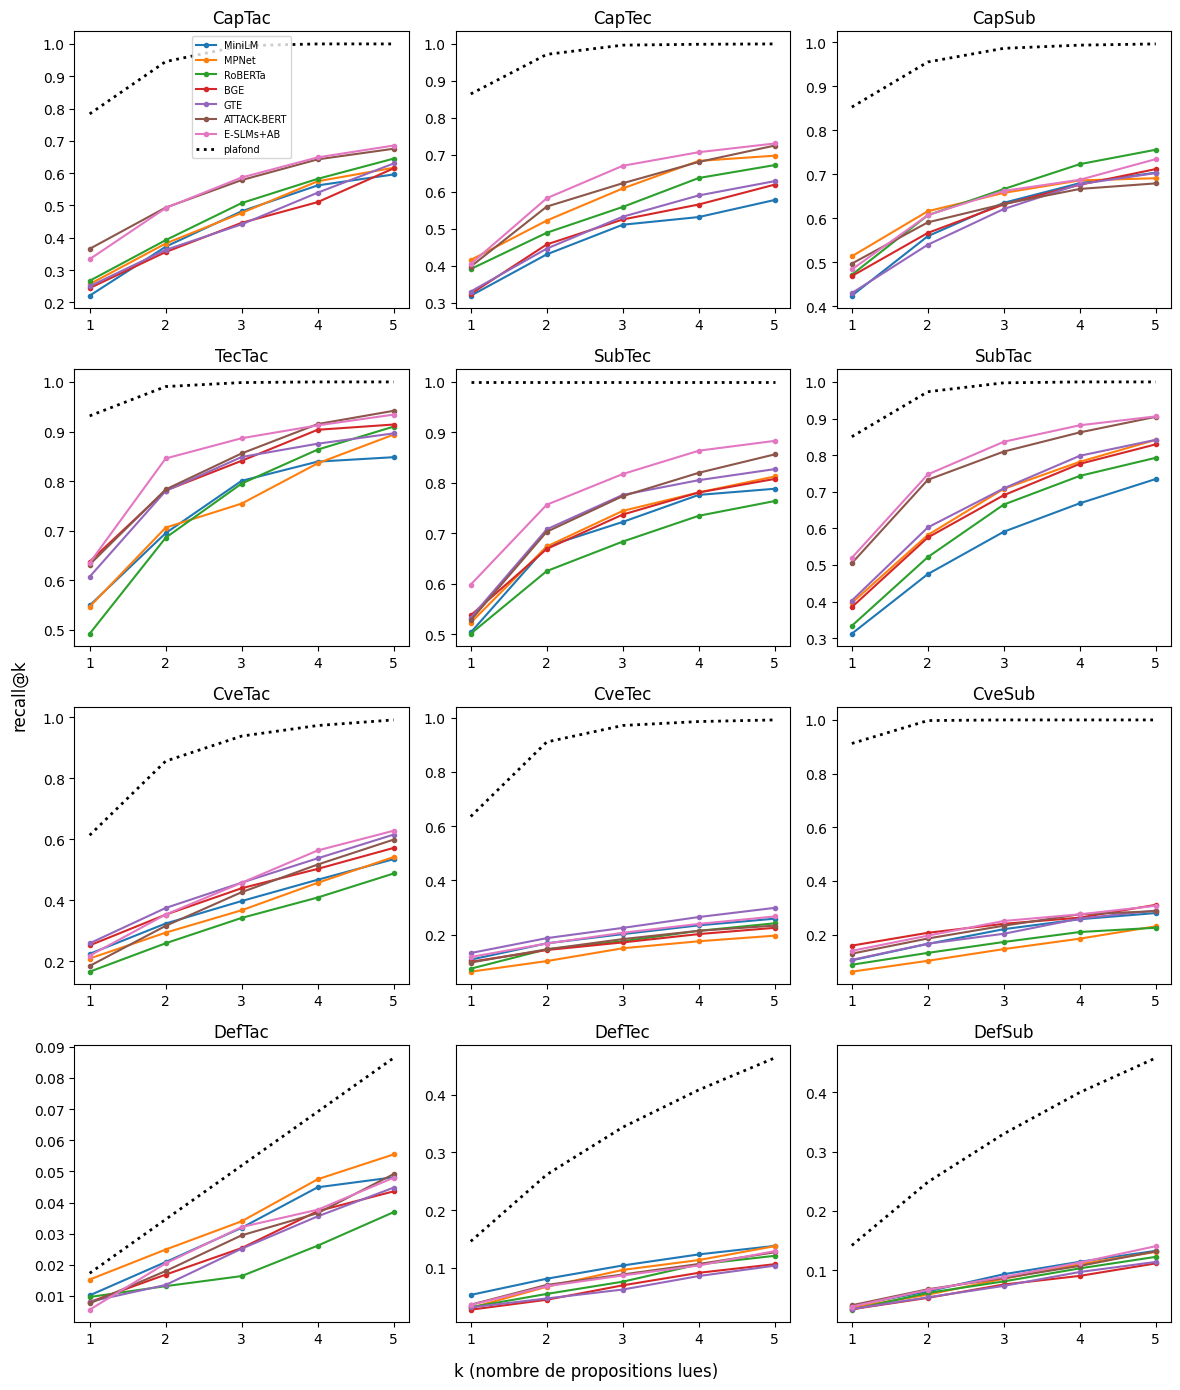

In [ ]:
import matplotlib.pyplot as plt

GRILLE = [["CapTac", "CapTec", "CapSub"],
          ["TecTac", "SubTec", "SubTac"],
          ["CveTac", "CveTec", "CveSub"],
          ["DefTac", "DefTec", "DefSub"]]
METHODES_FIG = ["MiniLM", "MPNet", "RoBERTa", "BGE", "GTE", "ATTACK-BERT", "E-SLMs+AB"]
ks = [1, 2, 3, 4, 5]

fig, axes = plt.subplots(4, 3, figsize=(12, 14))
for i, ligne in enumerate(GRILLE):
    for j, nom_tache in enumerate(ligne):
        ax = axes[i][j]
        for m in METHODES_FIG:
            S, Y = charger_S(m, nom_tache)
            ax.plot(ks, [recall_at_k(Y, S, k) for k in ks], marker="o", markersize=3, label=m)
        p = Y.sum(axis=1)
        ax.plot(ks, [np.mean(np.minimum(k, p) / p) for k in ks], "k:", linewidth=2, label="plafond")
        ax.set_title(nom_tache)
        ax.set_xticks(ks)
axes[0][0].legend(fontsize=7)
fig.supxlabel("k (nombre de propositions lues)")
fig.supylabel("recall@k")
fig.tight_layout()
fig.savefig(f"{DOSSIER}/figure4.png", dpi=150)
plt.show()

#Étape 10 : ta contribution

La reproduction a fait apparaître des observations. La contribution consiste à les transformer en résultats démontrés, puis à proposer une amélioration.

#1 Les métriques par requête et le recall normalisé

Jusqu’ici, evaluer donnait une moyenne par sous-tâche. Pour mesurer une incertitude et faire des tests, il nous faut la valeur de chaque requête.

par_requete renvoie, pour chaque requête, son recall@5, son recall@5 normalisé et son LRAP. On obtient donc un tableau de valeurs, et non plus une seule moyenne.
charger_S(m, t) renvoie (S, Y), alors que par_requete attend (Y, S). [::-1] inverse l’ordre des deux, et l’étoile * les passe comme deux arguments séparés.
Le recall normalisé (nR@5) divise le nombre de bonnes réponses trouvées par min(5, p), c’est-à-dire par ce qu’un modèle parfait trouverait. 1 veut dire parfait, sur toutes les sous-tâches. Avec le recall@5 classique, un modèle parfait plafonne à 0,086 sur DefTac. Avec le recall normalisé, il obtient 1. Toutes les sous-tâches deviennent ainsi comparables entre elles.
Le hasard est calculé par requête, en moyenne sur 20 tirages, pour pouvoir le comparer requête par requête.

In [2]:
from sklearn.metrics import label_ranking_average_precision_score

def par_requete(Y, S, k=5):
    ordre = np.argsort(-S, axis=1)
    Y_trie = np.take_along_axis(Y, ordre, axis=1)
    p = Y.sum(axis=1)
    trouves = Y_trie[:, :k].sum(axis=1)
    lrap = np.array([label_ranking_average_precision_score(Y[i:i+1], S[i:i+1])
                     for i in range(len(Y))])
    return {"R@5": trouves / p,
            "nR@5": trouves / np.minimum(k, p),
            "LRAP": lrap}

METHODES = ["MiniLM", "MPNet", "RoBERTa", "BGE", "GTE", "ATTACK-BERT", "E-SLMs+AB"]
PQ = {}
for m in METHODES:
    PQ[m] = {t: par_requete(*charger_S(m, t)[::-1]) for t in TACHES}

for t in TACHES:
    tr, te, Y = preparer(TACHES[t])
    PQ.setdefault("TF-IDF", {})[t] = par_requete(Y, similarites_tfidf(tr, te))
    rng = np.random.default_rng(0)
    tirages = [par_requete(Y, rng.random(Y.shape)) for _ in range(20)]
    PQ.setdefault("Hasard", {})[t] = {k: np.mean([d[k] for d in tirages], axis=0)
                                      for k in ["R@5", "nR@5", "LRAP"]}

def tableau_pq(metrique, methodes):
    df = pd.DataFrame({m: {t: PQ[m][t][metrique].mean() for t in TACHES}
                       for m in methodes}).T
    df["Moyenne"] = df.mean(axis=1)
    return df.round(3)

display(tableau_pq("nR@5", ["Hasard", "TF-IDF"] + METHODES))

,TecTac,SubTec,SubTac,CapTac,CapTec,CapSub,CveTac,CveTec,CveSub,DefTac,DefTec,DefSub,Moyenne
Hasard,0.352,0.027,0.353,0.350,0.027,0.010,0.360,0.025,0.011,0.478,0.127,0.119,0.187
TF-IDF,0.863,0.781,0.751,0.432,0.535,0.618,0.599,0.178,0.249,0.550,0.328,0.279,0.514
MiniLM,0.848,0.788,0.735,0.596,0.578,0.706,0.540,0.259,0.280,0.600,0.366,0.362,0.555
MPNet,0.894,0.813,0.842,0.617,0.698,0.693,0.547,0.197,0.231,0.667,0.402,0.366,0.580
RoBERTa,0.910,0.764,0.793,0.645,0.672,0.758,0.493,0.242,0.226,0.483,0.322,0.328,0.553
BGE,0.914,0.808,0.829,0.615,0.619,0.714,0.578,0.226,0.311,0.567,0.278,0.291,0.562
GTE,0.896,0.827,0.842,0.630,0.629,0.706,0.622,0.299,0.290,0.567,0.293,0.316,0.576
ATTACK-BERT,0.942,0.856,0.905,0.676,0.725,0.681,0.605,0.234,0.287,0.600,0.359,0.365,0.603
E-SLMs+AB,0.934,0.883,0.906,0.685,0.730,0.736,0.634,0.268,0.307,0.583,0.366,0.374,0.617


#2 Les intervalles de confiance (bootstrap)

Nos requêtes ne sont qu’un échantillon : avec d’autres techniques ou d’autres CVE, la moyenne aurait été un peu différente. Le bootstrap mesure cette incertitude par simulation :

on tire au hasard, avec remise, autant de requêtes qu’il y en a. Certaines reviennent plusieurs fois, d’autres sont absentes ;
on calcule la moyenne de ce nouvel échantillon ;
on recommence 2 000 fois ;
on garde l’intervalle qui contient 95 % de ces moyennes : du quantile 2,5 % au quantile 97,5 %.

rng.integers(0, len(valeurs), size=(n, len(valeurs))) fait d’un coup les 2 000 tirages d’indices. La graine 0 rend le résultat reproductible.

In [3]:
def bootstrap_ic(valeurs, n=2000, graine=0):
    rng = np.random.default_rng(graine)
    tirages = rng.integers(0, len(valeurs), size=(n, len(valeurs)))
    moyennes = valeurs[tirages].mean(axis=1)
    return valeurs.mean(), np.quantile(moyennes, 0.025), np.quantile(moyennes, 0.975)

lignes = {}
for m in ["TF-IDF", "ATTACK-BERT", "E-SLMs+AB"]:
    lignes[m] = {}
    for t in TACHES:
        moy, bas, haut = bootstrap_ic(PQ[m][t]["LRAP"])
        lignes[m][t] = f"{moy:.3f} [{bas:.3f} ; {haut:.3f}]"

ic = pd.DataFrame(lignes)
display(ic)
ic.to_csv(f"{DOSSIER}/intervalles_confiance_LRAP.csv")

,TF-IDF,ATTACK-BERT,E-SLMs+AB
TecTac,0.667 [0.617 ; 0.715],0.780 [0.735 ; 0.822],0.795 [0.753 ; 0.837]
SubTec,0.632 [0.594 ; 0.670],0.673 [0.637 ; 0.706],0.726 [0.693 ; 0.758]
SubTac,0.585 [0.552 ; 0.620],0.731 [0.702 ; 0.760],0.746 [0.716 ; 0.775]
CapTac,0.323 [0.285 ; 0.365],0.577 [0.530 ; 0.627],0.563 [0.514 ; 0.614]
CapTec,0.406 [0.351 ; 0.463],0.569 [0.512 ; 0.624],0.586 [0.531 ; 0.638]
CapSub,0.480 [0.408 ; 0.554],0.620 [0.544 ; 0.698],0.632 [0.559 ; 0.705]
CveTac,0.451 [0.430 ; 0.471],0.477 [0.457 ; 0.496],0.510 [0.491 ; 0.530]
CveTec,0.139 [0.125 ; 0.152],0.197 [0.179 ; 0.214],0.223 [0.204 ; 0.242]
CveSub,0.181 [0.148 ; 0.216],0.217 [0.180 ; 0.254],0.235 [0.199 ; 0.274]
DefTac,0.519 [0.432 ; 0.608],0.556 [0.487 ; 0.629],0.554 [0.484 ; 0.628]


#3 : les tests statistiques appariés

But. Répondre rigoureusement à trois questions :

L’ensemble E-SLMs+AB est-il significativement meilleur qu’ATTACK-BERT ?
ATTACK-BERT est-il significativement meilleur que TF-IDF ? C’est ton hypothèse H3.
L’avance d’ATTACK-BERT sur le meilleur généraliste ne concerne-t-elle que les tactiques ? C’est ton hypothèse H1.

#3.1 Le test de permutation apparié

d = a - b : pour chaque requête, on calcule la différence de score entre les deux modèles. C’est ce qui rend le test « apparié » : on compare les modèles requête par requête, et non deux moyennes globales.
observe : l’écart moyen réellement observé.
L’idée du test. Si les deux modèles étaient en réalité équivalents, le signe de chaque différence serait dû au hasard. Le modèle 1 gagnerait parfois, le modèle 2 parfois. On simule donc ce monde « sans différence » en retournant au hasard le signe de chaque différence (signes vaut +1 ou −1), et ce 10 000 fois.
La p-valeur est la proportion de ces 10 000 simulations où le hasard produit un écart au moins aussi grand que l’écart observé. Le +1 en haut et en bas évite une p-valeur exactement nulle, ce qui serait faux avec un nombre fini de simulations.

Comment lire une p-valeur : si p < 0,05, un écart aussi grand n’apparaît que rarement par hasard (moins de 5 fois sur 100). On dit alors que la différence est significative.

In [4]:
def test_apparie(a, b, n=10000, graine=0):
    rng = np.random.default_rng(graine)
    d = a - b
    observe = abs(d.mean())
    signes = rng.choice([-1, 1], size=(n, len(d)))
    hasard = np.abs((signes * d).mean(axis=1))
    return d.mean(), (np.sum(hasard >= observe) + 1) / (n + 1)

#3.2 La correction de Holm

Pourquoi c’est nécessaire. On fait 12 tests, un par sous-tâche. Avec un seuil de 5 %, on a environ une chance sur deux d’obtenir au moins un faux « significatif » par pur hasard (1 − 0,95¹² ≈ 46 %). La correction de Holm rend chaque test plus exigeant pour compenser.

Comment elle fonctionne :

on trie les p-valeurs de la plus petite à la plus grande ;
on multiplie la plus petite par 12, la suivante par 11, etc. ;
on s’assure que l’ordre est respecté, grâce à max(courant, …).

Résultat attendu du petit test : [0.03 0.06 0.06 0.02]. Vérifions à la main : la plus petite, 0,005, est multipliée par 4 et donne 0,02. Puis 0,01 × 3 = 0,03, puis 0,03 × 2 = 0,06. Enfin 0,04 × 1 = 0,04, qui remonte à 0,06 pour respecter l’ordre. Comme à l’étape 4, on valide la fonction sur un exemple dont on connaît le résultat.

In [5]:
def holm(pvaleurs):
    pvaleurs = np.asarray(pvaleurs)
    m = len(pvaleurs)
    ajustees = np.empty(m)
    courant = 0.0
    for rang, i in enumerate(np.argsort(pvaleurs)):
        courant = max(courant, min(1.0, (m - rang) * pvaleurs[i]))
        ajustees[i] = courant
    return ajustees

print(holm([0.01, 0.04, 0.03, 0.005]))

[0.03 0.06 0.06 0.02]


#3.3 Comparer deux modèles sur les 12 sous-tâches

Pour chaque sous-tâche, on compare les deux modèles requête par requête, puis on corrige les 12 p-valeurs avec Holm.
L’écart est positif si le premier modèle est meilleur, négatif sinon.
On choisit GTE pour H1 parce que c’est le meilleur généraliste en moyenne (nR@5 de 0,576, LRAP égal à celui de BGE).
On sauvegarde les trois tableaux sur Drive pour ton mémoire.
Le calcul prend quelques secondes et ne demande pas de GPU.

In [6]:
def comparer(m1, m2, metrique="LRAP"):
    lignes = []
    for t in TACHES:
        ecart, p = test_apparie(PQ[m1][t][metrique], PQ[m2][t][metrique])
        lignes.append({"sous-tâche": t, "écart": ecart, "p": p})
    df = pd.DataFrame(lignes).set_index("sous-tâche")
    df["p (Holm)"] = holm(df["p"].values)
    df["significatif"] = df["p (Holm)"] < 0.05
    return df.round(4)

print("1. L'ensemble est-il meilleur qu'ATTACK-BERT ?")
c1 = comparer("E-SLMs+AB", "ATTACK-BERT"); display(c1)

print("2. ATTACK-BERT est-il meilleur que TF-IDF ? (H3)")
c2 = comparer("ATTACK-BERT", "TF-IDF"); display(c2)

print("3. ATTACK-BERT est-il meilleur que GTE ? (H1)")
c3 = comparer("ATTACK-BERT", "GTE"); display(c3)

for nom, df in [("ensemble_vs_AB", c1), ("AB_vs_TFIDF", c2), ("AB_vs_GTE", c3)]:
    df.to_csv(f"{DOSSIER}/test_{nom}.csv")

1. L'ensemble est-il meilleur qu'ATTACK-BERT ?


,écart,p,p (Holm),significatif
sous-tâche,,,,
TecTac,0.0145,0.1158,0.8105,False
SubTec,0.0527,0.0001,0.0012,True
SubTac,0.0149,0.0244,0.2196,False
CapTac,-0.0141,0.1464,0.8471,False
CapTec,0.0175,0.1412,0.8471,False
CapSub,0.0124,0.2612,0.8471,False
CveTac,0.0335,0.0001,0.0012,True
CveTec,0.0267,0.0001,0.0012,True
CveSub,0.0184,0.0406,0.3248,False


2. ATTACK-BERT est-il meilleur que TF-IDF ? (H3)


,écart,p,p (Holm),significatif
sous-tâche,,,,
TecTac,0.1136,0.0001,0.0012,True
SubTec,0.0405,0.0360,0.1440,False
SubTac,0.1459,0.0001,0.0012,True
CapTac,0.2543,0.0001,0.0012,True
CapTec,0.1624,0.0001,0.0012,True
CapSub,0.1397,0.0002,0.0012,True
CveTac,0.0261,0.0219,0.1095,False
CveTec,0.0580,0.0001,0.0012,True
CveSub,0.0360,0.0621,0.1863,False


3. ATTACK-BERT est-il meilleur que GTE ? (H1)


,écart,p,p (Holm),significatif
sous-tâche,,,,
TecTac,0.0222,0.2907,0.8720,False
SubTec,0.0047,0.7854,0.8720,False
SubTac,0.1023,0.0001,0.0012,True
CapTac,0.1098,0.0001,0.0012,True
CapTec,0.0813,0.0017,0.0102,True
CapSub,0.0446,0.1625,0.8124,False
CveTac,-0.0451,0.0002,0.0014,True
CveTec,-0.0434,0.0001,0.0012,True
CveSub,0.0241,0.1959,0.8124,False


In [7]:
# ===== Cellule 11.1 — Export des résultats par requête pour le chapitre 5 =====
import json, os

# Si Colab s'est déconnecté : exécute d'abord la cellule de reprise rapide,
# puis la cellule 10 jusqu'à la construction de PQ (inclus).
assert "PQ" in globals(), "PQ n'existe pas : relance la cellule 10."

export = {
    m: {t: {k: [float(x) for x in PQ[m][t][k]] for k in PQ[m][t]} for t in PQ[m]}
    for m in PQ
}

chemin = f"{DOSSIER}/PQ_par_requete.json"
with open(chemin, "w") as f:
    json.dump(export, f)

# Contrôle : on affiche le nR@5 moyen par méthode
for m in export:
    moy = sum(sum(export[m][t]["nR@5"]) / len(export[m][t]["nR@5"]) for t in export[m]) / len(export[m])
    print(f"{m:12s} nR@5 moyen = {moy:.3f}  ({len(export[m])} sous-tâches)")
print("Fichier :", chemin, "-", os.path.getsize(chemin) // 1024, "Ko")

MiniLM       nR@5 moyen = 0.555  (12 sous-tâches)
MPNet        nR@5 moyen = 0.580  (12 sous-tâches)
RoBERTa      nR@5 moyen = 0.553  (12 sous-tâches)
BGE          nR@5 moyen = 0.562  (12 sous-tâches)
GTE          nR@5 moyen = 0.576  (12 sous-tâches)
ATTACK-BERT  nR@5 moyen = 0.603  (12 sous-tâches)
E-SLMs+AB    nR@5 moyen = 0.617  (12 sous-tâches)
TF-IDF       nR@5 moyen = 0.514  (12 sous-tâches)
Hasard       nR@5 moyen = 0.187  (12 sous-tâches)
Fichier : /content/drive/MyDrive/memoire_sts/resultats/PQ_par_requete.json - 946 Ko


In [2]:
# ===== Cellule 12.1 — Longueur des textes en jetons, pour chaque modèle =====
from transformers import AutoTokenizer
import numpy as np, pandas as pd, json

assert "TACHES" in globals(), "Exécute d'abord la cellule de reprise rapide."

IDS = {"MiniLM":      "sentence-transformers/all-MiniLM-L12-v2",
       "MPNet":       "sentence-transformers/all-mpnet-base-v2",
       "RoBERTa":     "sentence-transformers/all-roberta-large-v1",
       "BGE":         "BAAI/bge-large-en-v1.5",
       "GTE":         "thenlper/gte-large",
       "ATTACK-BERT": "basel/ATTACK-BERT"}
LIMITES = {"MiniLM": 128, "MPNet": 384, "RoBERTa": 256,
           "BGE": 512, "GTE": 512, "ATTACK-BERT": 384}

# Les textes de chaque type d'entité (chaque entité comptée une seule fois)
GROUPES = {
    "Tactiques":       TACHES["TecTac"]["etiquettes"],
    "Techniques":      TACHES["TecTac"]["requetes"],
    "Sous-techniques": TACHES["SubTec"]["requetes"],
    "CAPEC":           TACHES["CapTac"]["requetes"],
    "CVE":             TACHES["CveTac"]["requetes"],
    "Contre-mesures":  TACHES["DefTac"]["etiquettes"],
}
textes = {g: [e["texte"] for e in ents.values()] for g, ents in GROUPES.items()}

longueurs = {}
for m, hf_id in IDS.items():
    tok = AutoTokenizer.from_pretrained(hf_id)
    longueurs[m] = {g: [len(ids) for ids in tok(t, add_special_tokens=True)["input_ids"]]
                    for g, t in textes.items()}

# Tableau 1 : longueur médiane (en jetons) de chaque type de texte
med = pd.DataFrame({m: {g: int(np.median(v)) for g, v in longueurs[m].items()} for m in IDS})
# Tableau 2 : % de textes plus longs que la limite du modèle (donc tronqués)
coupe = pd.DataFrame({m: {g: round(100 * np.mean(np.array(v) > LIMITES[m]), 1)
                          for g, v in longueurs[m].items()} for m in IDS})

print("Nombre de textes :", {g: len(t) for g, t in textes.items()})
print("\n=== Longueur médiane (jetons) ===");            print(med.to_string())
print("\n=== % de textes tronqués par chaque modèle ==="); print(coupe.to_string())

json.dump({"longueurs": longueurs, "limites": LIMITES},
          open(f"{DOSSIER}/longueurs.json", "w"))
print("\nSauvegardé :", f"{DOSSIER}/longueurs.json")

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/352 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (570 > 512). Running this sequence through the model will result in indexing errors


Nombre de textes : {'Tactiques': 14, 'Techniques': 196, 'Sous-techniques': 411, 'CAPEC': 177, 'CVE': 815, 'Contre-mesures': 139}

=== Longueur médiane (jetons) ===
                 MiniLM  MPNet  RoBERTa  BGE  GTE  ATTACK-BERT
Tactiques            99     99       94   99   99           99
Techniques          176    176      172  176  176          176
Sous-techniques     205    205      198  205  205          205
CAPEC               109    109      107  109  109          109
CVE                  78     78       76   78   78           78
Contre-mesures       23     23       23   23   23           23

=== % de textes tronqués par chaque modèle ===
                 MiniLM  MPNet  RoBERTa  BGE  GTE  ATTACK-BERT
Tactiques           7.1    0.0      0.0  0.0  0.0          0.0
Techniques         74.0    5.6     20.9  1.5  1.5          5.6
Sous-techniques    86.9    9.2     29.7  2.2  2.2          9.2
CAPEC              44.6    2.3      9.6  0.6  0.6          2.3
CVE                15.2    0.6  

In [2]:
# ===== Cellule 12.2 — Expérience de troncature =====
import os, time, json, torch, numpy as np, pandas as pd
from sentence_transformers import SentenceTransformer
from sklearn.metrics import label_ranking_average_precision_score as lrap_score

assert "TACHES" in globals(), "Exécute d'abord la cellule de reprise rapide."
assert torch.cuda.is_available(), "Active le GPU (Exécution > Modifier le type d'exécution)."

IDS = {"MiniLM":      "sentence-transformers/all-MiniLM-L12-v2",
       "MPNet":       "sentence-transformers/all-mpnet-base-v2",
       "RoBERTa":     "sentence-transformers/all-roberta-large-v1",
       "BGE":         "BAAI/bge-large-en-v1.5",
       "GTE":         "thenlper/gte-large",
       "ATTACK-BERT": "basel/ATTACK-BERT"}

# Modèle -> longueurs testées (la première est la longueur d'origine)
CONFIGS = {"MiniLM":      [128, 256, 512],
           "MPNet":       [384, 128],
           "RoBERTa":     [256, 128, 512],
           "BGE":         [512, 128],
           "GTE":         [512, 128],
           "ATTACK-BERT": [384, 128]}

# 1. Tous les textes distincts, une seule fois (identifiant -> texte)
TEXTES = {}
for t in TACHES.values():
    for d in (t["requetes"], t["etiquettes"]):
        for i, e in d.items():
            TEXTES[i] = e["texte"]
ids_tous = list(TEXTES)
pos = {i: k for k, i in enumerate(ids_tous)}
print(len(ids_tous), "textes distincts")

def matrices(tache):
    q, l = list(tache["requetes"]), list(tache["etiquettes"])
    Y = np.array([[1 if e in tache["verite"][r] else 0 for e in l] for r in q])
    return q, l, Y

def lrap_par_requete(Y, S):
    return np.array([lrap_score(Y[i:i+1], S[i:i+1]) for i in range(len(Y))])

# 2. Reprise si une partie a déjà été calculée
FICHIER_T = f"{DOSSIER}/troncature.json"
res_t = json.load(open(FICHIER_T)) if os.path.exists(FICHIER_T) else {}

# 3. Boucle principale
for m, longueurs_test in CONFIGS.items():
    a_faire = [L for L in longueurs_test if f"{m}@{L}" not in res_t]
    if not a_faire:
        print(m, ": déjà fait"); continue
    modele = SentenceTransformer(IDS[m], device="cuda")
    for L in a_faire:
        t0 = time.time()
        modele.max_seq_length = L
        E = modele.encode([TEXTES[i] for i in ids_tous], batch_size=32,
                          normalize_embeddings=True, convert_to_numpy=True,
                          show_progress_bar=False)
        res_t[f"{m}@{L}"] = {}
        for nom, tache in TACHES.items():
            q, l, Y = matrices(tache)
            S = E[[pos[i] for i in q]] @ E[[pos[i] for i in l]].T
            res_t[f"{m}@{L}"][nom] = lrap_par_requete(Y, S).tolist()
        json.dump(res_t, open(FICHIER_T, "w"))          # sauvegarde après chaque configuration
        moy = np.mean([np.mean(v) for v in res_t[f"{m}@{L}"].values()])
        print(f"{m}@{L:<4d} LRAP moyen = {moy:.3f}   ({time.time() - t0:.0f} s)")
    del modele; torch.cuda.empty_cache()

# 4. Tableau récapitulatif : LRAP par sous-tâche pour chaque configuration
tab = pd.DataFrame({cle: {t: np.mean(v) for t, v in r.items()} for cle, r in res_t.items()}).T
tab["Moyenne"] = tab.mean(axis=1)
pd.set_option("display.width", 200)
print("\n=== LRAP par configuration (modèle@longueur) ===")
print(tab.round(3).to_string())
print("\nSauvegardé :", FICHIER_T)

1752 textes distincts


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

ATTACK-BERT@384  LRAP moyen = 0.501   (27 s)
ATTACK-BERT@128  LRAP moyen = 0.492   (16 s)

=== LRAP par configuration (modèle@longueur) ===
                 TecTac  SubTec  SubTac  CapTac  CapTec  CapSub  CveTac  CveTec  CveSub  DefTac  DefTec  DefSub  Moyenne
MiniLM@128        0.703   0.640   0.528   0.445   0.467   0.584   0.466   0.215   0.195   0.553   0.299   0.300    0.449
MiniLM@256        0.694   0.636   0.563   0.459   0.513   0.572   0.471   0.186   0.187   0.555   0.298   0.298    0.453
MiniLM@512        0.704   0.633   0.570   0.456   0.521   0.566   0.471   0.182   0.212   0.555   0.297   0.297    0.455
MPNet@384         0.704   0.654   0.620   0.471   0.565   0.636   0.451   0.160   0.150   0.570   0.303   0.310    0.466
MPNet@128         0.705   0.661   0.591   0.459   0.487   0.626   0.447   0.150   0.147   0.568   0.303   0.308    0.454
RoBERTa@256       0.683   0.623   0.573   0.495   0.538   0.628   0.414   0.187   0.163   0.561   0.282   0.286    0.453
RoBERTa@128  

In [4]:
import torch
libre, total = torch.cuda.mem_get_info()
print(f"GPU libre : {libre/1e9:.1f} Go sur {total/1e9:.1f} Go")

GPU libre : 15.0 Go sur 15.6 Go


In [5]:
# ===== Cellule 13.1 — Affinage de MPNet sur les CVE (validation croisée en 5 parties) =====
import os, json, time, gc, torch, numpy as np, pandas as pd
import sentence_transformers
from datasets import Dataset
from sklearn.model_selection import KFold
from sklearn.metrics import label_ranking_average_precision_score as lrap_score
from sentence_transformers import (SentenceTransformer, SentenceTransformerTrainer,
                                   SentenceTransformerTrainingArguments, losses)
from sentence_transformers.training_args import BatchSamplers

print("sentence-transformers", sentence_transformers.__version__)   # doit être >= 3.0
assert torch.cuda.is_available(), "Active le GPU."

NOM, HF = "MPNet", "sentence-transformers/all-mpnet-base-v2"
K, GRAINE, EPOQUES, LR, LOT = 5, 0, 3, 2e-5, 32
TACHES_CVE = ["CveTac", "CveTec", "CveSub"]

cves = sorted(TACHES["CveTac"]["requetes"])                 # les 815 CVE
texte = {}
for t in TACHES_CVE:
    for d in (TACHES[t]["requetes"], TACHES[t]["etiquettes"]):
        for i, e in d.items():
            texte[i] = e["texte"]

def paires(ids_cve):
    """Paires (CVE, technique) et (CVE, sous-technique) — jamais les tactiques."""
    a, p = [], []
    for c in ids_cve:
        for t in ["CveTec", "CveSub"]:
            for l in sorted(TACHES[t]["verite"].get(c, [])):
                a.append(texte[c]); p.append(texte[l])
    return Dataset.from_dict({"anchor": a, "positive": p})

def evaluer_cve(modele, ids_test):
    """Scores par CVE (LRAP, R@5, nR@5) sur les trois sous-tâches CVE."""
    out = {}
    for t in TACHES_CVE:
        q = [c for c in TACHES[t]["requetes"] if c in ids_test]
        l = list(TACHES[t]["etiquettes"])
        Eq = modele.encode([texte[c] for c in q], normalize_embeddings=True, batch_size=64)
        El = modele.encode([texte[x] for x in l], normalize_embeddings=True, batch_size=64)
        S = Eq @ El.T
        Y = np.array([[1 if x in TACHES[t]["verite"][c] else 0 for x in l] for c in q])
        top = np.argsort(-S, axis=1)[:, :5]
        trouves, p = np.take_along_axis(Y, top, axis=1).sum(1), Y.sum(1)
        out[t] = {c: {"LRAP": float(lrap_score(Y[i:i+1], S[i:i+1])),
                      "R@5":  float(trouves[i] / p[i]),
                      "nR@5": float(trouves[i] / min(5, p[i]))} for i, c in enumerate(q)}
    return out

FICHIER_A = f"{DOSSIER}/affinage_{NOM}.json"
res_a = json.load(open(FICHIER_A)) if os.path.exists(FICHIER_A) else {"base": {}, "affine": {}, "plis": {}}

# 1. Le modèle de base, non affiné, sur toutes les CVE (point de comparaison)
if not res_a["base"]:
    base = SentenceTransformer(HF, device="cuda")
    res_a["base"] = evaluer_cve(base, set(cves))
    json.dump(res_a, open(FICHIER_A, "w"))
    del base; torch.cuda.empty_cache()
print("Base — LRAP :", {t: round(np.mean([v["LRAP"] for v in res_a["base"][t].values()]), 3) for t in TACHES_CVE})

# 2. Validation croisée : entraîner sur 4/5 des CVE, évaluer sur le 1/5 restant
kf = KFold(n_splits=K, shuffle=True, random_state=GRAINE)
for f, (i_tr, i_te) in enumerate(kf.split(cves)):
    if str(f) in res_a["plis"]:
        print(f"pli {f} : déjà fait"); continue
    t0 = time.time()
    tr = [cves[i] for i in i_tr]; te = {cves[i] for i in i_te}
    assert not te & set(tr), "Fuite : une CVE de test est dans l'entraînement !"
    donnees = paires(tr)
    modele = SentenceTransformer(HF, device="cuda")
    args = SentenceTransformerTrainingArguments(
        output_dir=f"/content/tmp_affinage_{f}", num_train_epochs=EPOQUES,
        per_device_train_batch_size=LOT, learning_rate=LR, warmup_ratio=0.1,
        fp16=True, batch_sampler=BatchSamplers.NO_DUPLICATES,
        save_strategy="no", logging_steps=25, report_to="none", seed=GRAINE)
    entraineur = SentenceTransformerTrainer(model=modele, args=args, train_dataset=donnees,
                                            loss=losses.CachedMultipleNegativesRankingLoss(modele, mini_batch_size=8))
    entraineur.train()
    r = evaluer_cve(modele, te)
    for t in r:
        res_a["affine"].setdefault(t, {}).update(r[t])
    res_a["plis"][str(f)] = sorted(te)
    json.dump(res_a, open(FICHIER_A, "w"))
    print(f"pli {f} : {len(tr)} CVE d'entraînement, {len(te)} de test, "
          f"{len(donnees)} paires — {time.time() - t0:.0f} s")
    del entraineur, modele; gc.collect(); torch.cuda.empty_cache()

# 3. Comparaison base / affiné sur les mêmes CVE
lignes = {}
for t in TACHES_CVE:
    ids = list(res_a["affine"][t])
    for met in ["LRAP", "nR@5"]:
        b = np.mean([res_a["base"][t][c][met] for c in ids])
        a = np.mean([res_a["affine"][t][c][met] for c in ids])
        lignes[(t, met)] = {"requêtes": len(ids), "base": round(b, 3),
                            "affiné": round(a, 3), "écart": round(a - b, 3)}
print("\n=== MPNet de base contre MPNet affiné (CVE jamais vues à l'entraînement) ===")
print(pd.DataFrame(lignes).T.to_string())
print("\nSauvegardé :", FICHIER_A)

sentence-transformers 5.7.0
Base — LRAP : {'CveTac': np.float64(0.451), 'CveTec': np.float64(0.16), 'CveSub': np.float64(0.15)}


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss
25,3.101189
50,2.299332
75,2.376188
100,1.979436
125,2.096217
150,1.901086


pli 0 : 652 CVE d'entraînement, 163 de test, 1613 paires — 217 s


...

pli 3 : 652 CVE d'entraînement, 163 de test, 1564 paires — 192 s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss
25,3.066347
50,2.217502
75,2.402296
100,1.965748
125,2.132845
150,1.771375


pli 4 : 652 CVE d'entraînement, 163 de test, 1581 paires — 199 s

=== MPNet de base contre MPNet affiné (CVE jamais vues à l'entraînement) ===
             requêtes   base  affiné  écart
CveTac LRAP     815.0  0.451   0.480  0.028
       nR@5     815.0  0.547   0.543 -0.003
CveTec LRAP     815.0  0.160   0.314  0.154
       nR@5     815.0  0.197   0.405  0.208
CveSub LRAP     283.0  0.150   0.309  0.159
       nR@5     283.0  0.231   0.429  0.198

Sauvegardé : /content/drive/MyDrive/memoire_sts/resultats/affinage_MPNet.json


In [6]:
# ===== Cellule 13.2 — Référence « popularité » et analyse selon la fréquence des étiquettes =====
import json, collections, numpy as np, pandas as pd
from sklearn.metrics import label_ranking_average_precision_score as lrap_score

res_a = json.load(open(f"{DOSSIER}/affinage_MPNet.json"))
PQ_   = json.load(open(f"{DOSSIER}/PQ_par_requete.json"))

def popularite(T):
    """Classe les étiquettes selon leur fréquence dans les CVE d'entraînement du pli,
    sans lire aucun texte : c'est la même liste pour toutes les CVE de test."""
    q, l = list(TACHES[T]["requetes"]), list(TACHES[T]["etiquettes"])
    bruit = np.random.default_rng(0).random(len(l)) * 1e-3     # départage les égalités
    out = {}
    for f, te in res_a["plis"].items():
        te = set(te)
        compte = collections.Counter(x for c in q if c not in te for x in TACHES[T]["verite"][c])
        S = np.array([compte[x] for x in l], float) + bruit
        for c in q:
            if c in te:
                y = np.array([[1 if x in TACHES[T]["verite"][c] else 0 for x in l]])
                out[c] = lrap_score(y, S[None])
    return out

lignes, groupes = {}, {}
for T in ["CveTac", "CveTec", "CveSub"]:
    q    = list(TACHES[T]["requetes"])
    pop  = popularite(T)
    base = np.array([res_a["base"][T][c]["LRAP"] for c in q])
    aff  = np.array([res_a["affine"][T][c]["LRAP"] for c in q])
    popa = np.array([pop[c] for c in q])
    gte  = np.array(PQ_["GTE"][T]["LRAP"])
    lignes[T] = {"MPNet base": base.mean(), "MPNet affiné": aff.mean(),
                 "Popularité": popa.mean(), "GTE": gte.mean()}
    if T != "CveTac":
        compte = collections.Counter(x for v in TACHES[T]["verite"].values() for x in v)
        top10 = {k for k, _ in compte.most_common(10)}
        rare = np.array([not (set(TACHES[T]["verite"][c]) & top10) for c in q])
        for nom, m in [("rares", rare), ("fréquentes", ~rare)]:
            groupes[(T, nom)] = {"requêtes": int(m.sum()), "MPNet base": base[m].mean(),
                                 "MPNet affiné": aff[m].mean(), "Popularité": popa[m].mean(),
                                 "GTE": gte[m].mean()}

print("=== LRAP sur les CVE ===");                          print(pd.DataFrame(lignes).T.round(3))
print("\n=== Selon la fréquence des étiquettes ===");       print(pd.DataFrame(groupes).T.round(3))

=== LRAP sur les CVE ===
        MPNet base  MPNet affiné  Popularité    GTE
CveTac       0.451         0.480       0.600  0.522
CveTec       0.160         0.314       0.364  0.240
CveSub       0.150         0.309       0.510  0.193

=== Selon la fréquence des étiquettes ===
                   requêtes  MPNet base  MPNet affiné  Popularité    GTE
CveTec rares          121.0       0.180         0.398       0.053  0.209
       fréquentes     694.0       0.156         0.300       0.418  0.245
CveSub rares           41.0       0.186         0.319       0.032  0.241
       fréquentes     242.0       0.143         0.307       0.592  0.185
